# exp3_graded_alpha — dose-response analysis

Re-run of the manuscript's **Study 2**: the empathic weight α is graded over
{0, 0.25, 0.5, 0.75, 0.99}, emotion observation is always on, and — unlike the
manuscript — agents also observe the resource level `r_t / r_0`, under the
corrected training regime (persistent replay buffer, per-episode ε decay).

**Two metrics**

- **Depletion step** (`total_steps`) — how long the common pool survives. The
  episode terminates when `resource <= 0`, so this is literally the step at which
  the resource is depleted. *TH3: sustainability increases with α.*
- **Gini coefficient of access to the resource** (`gini_meals`) — inequality of
  meal counts across the 6 agents within an episode. *TH4: the manuscript
  predicted equality would increase with α, and found the opposite.*

**What the manuscript reported** (4 seeds per level, no `r_t`): Spearman
r_s(18) = .92 for resource lifetime and .96 for the Gini — TH3 confirmed, TH4
contradicted. This notebook re-tests both under the corrected regime.

Analyses use the **greedy evaluation episodes only** (`phase='eval'`, ε = 0, no
learning). Nothing is written to disk.

## 1. Setup

In [1]:
# statsmodels supplies the ANOVA / Tukey HSD machinery used below and is not
# part of this repo's base environment (see requirements.txt).
try:
    import statsmodels.api as _sm
except ImportError:
    %pip install statsmodels
    import importlib
    importlib.invalidate_caches()


In [2]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from IPython.display import display

EXPERIMENT = "exp3_graded_alpha"
RESULTS_DIR = Path("..") / "csv_results" / EXPERIMENT

LAST_N_EVAL = 10      # eval episodes averaged to define "end of training"
ALPHA_LEVEL = 0.05    # significance threshold
TARGET_SEEDS = 20     # replications requested by R2

print(f"experiment : {EXPERIMENT}")
print(f"data       : {RESULTS_DIR.resolve()}")


experiment : exp6_graded_alpha
data       : C:\Users\evann\OneDrive\Documents\1.neuro\ISIR\02_GT_AIS\csv_results\exp6_graded_alpha


In [3]:
# chart chrome: recessive grid and axes, text in neutral ink, series colour
# reserved for the marks themselves.
SURFACE = "#fcfcfb"
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "baseline": "#c3c2b7"}

# categorical slots (fixed order, never cycled)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
# ordinal blue ramp, steps 250-650: light end still clears 2:1 on this surface
ORDINAL_BLUE = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": INK["baseline"], "axes.linewidth": 1.0,
    "axes.labelcolor": INK["secondary"], "axes.labelsize": 10,
    "axes.titlecolor": INK["primary"], "axes.titlesize": 11,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": INK["grid"], "grid.linewidth": 0.8,
    "xtick.color": INK["muted"], "ytick.color": INK["muted"],
    "xtick.labelcolor": INK["secondary"], "ytick.labelcolor": INK["secondary"],
    "text.color": INK["primary"],
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2.0,
})

METRIC_LABEL = {
    "depletion_step": "Depletion step (steps before the pool empties)",
    "gini_meals": "Gini coefficient of meals",
    "total_meals": "Total meals consumed per episode",
}
METRICS = ["depletion_step", "gini_meals"]


## 2. Load the runs

Every condition parameter is a column of the summary CSVs, so loading is a plain glob + concat.

In [4]:
def load_summaries(results_dir: Path) -> pd.DataFrame:
    """Concatenate every *_episode_summary.csv of one experiment folder.

    The runner writes all condition parameters as columns, so no filename
    parsing is needed (unlike the older EUMAS notebooks).
    """
    files = sorted(results_dir.glob("*_episode_summary.csv"))
    if not files:
        raise FileNotFoundError(f"no *_episode_summary.csv under {results_dir.resolve()}")
    frames = []
    for path in files:
        one = pd.read_csv(path)
        one["source_file"] = path.name
        frames.append(one)
    return pd.concat(frames, ignore_index=True)


df = load_summaries(RESULTS_DIR)
print(f"{df['source_file'].nunique()} run files, {len(df)} episode rows\n")

inventory = (
    df.groupby("condition", observed=True)
      .agg(seeds=("seed", "nunique"),
           runs=("source_file", "nunique"),
           train_episodes=("phase", lambda s: int((s == "train").sum())),
           eval_episodes=("phase", lambda s: int((s == "eval").sum())))
      .sort_index()
)
inventory["seeds_missing_vs_target"] = TARGET_SEEDS - inventory["seeds"]
display(inventory)

if (inventory["seeds"] < TARGET_SEEDS).any():
    worst = int(inventory["seeds"].min())
    print(f"WARNING: only {worst}-{int(inventory['seeds'].max())} seeds per condition "
          f"(target {TARGET_SEEDS}). Every test below is underpowered; treat the "
          f"p-values as provisional until the full campaign has landed.")
else:
    print(f"All conditions at the {TARGET_SEEDS}-seed target.")


50 run files, 27500 episode rows



,seeds,runs,train_episodes,eval_episodes,seeds_missing_vs_target
condition,,,,,
alpha000_res,10,10,5000,500,10
alpha025_res,10,10,5000,500,10
alpha050_res,10,10,5000,500,10
alpha075_res,10,10,5000,500,10
alpha099_res,10,10,5000,500,10


## 3. Derived metrics and data integrity

Two things are checked before any test:

1. **Duplicated episodes** — a run written twice would silently inflate *n*.
2. **Right-censoring of the depletion step** — an episode that reaches
   `max_steps` with resource left never depleted the pool, so its "depletion
   step" is only a lower bound. This matters more here than in exp1: the high-α
   conditions are exactly the ones expected to hit the ceiling, so censoring is
   **not** independent of the factor under study.

In [5]:
# --- metrics -----------------------------------------------------------------
# depletion step: the episode ends when the pool hits 0 (env_gt_ais.py, done =
# resource <= 0), so total_steps IS the depletion step -- except when the
# episode is cut off at max_steps with resource left, which is right-censoring.
df["depletion_step"] = df["total_steps"]
df["censored"] = (df["total_steps"] >= df["max_steps"]) & (df["resource_remaining"] > 0)

meal_cols = [c for c in df.columns if re.fullmatch(r"meals_\d+", c)]
df["total_meals"] = df[meal_cols].sum(axis=1)

# final analyses use the greedy evaluation episodes only (epsilon = 0, no
# learning): the train rows carry exploration noise. See README.md.
ev = df[df["phase"] == "eval"].copy()

# --- integrity ---------------------------------------------------------------
dupes = int(df.duplicated(subset=["condition", "seed", "phase", "episode"]).sum())
eval_per_run = ev.groupby("source_file", observed=True).size()
print(f"duplicate (condition, seed, phase, episode) rows : {dupes}")
print(f"eval episodes per run : min {eval_per_run.min()}, max {eval_per_run.max()}")
print(f"agents per episode    : {len(meal_cols)}")
assert dupes == 0, "duplicated episode rows -- check for a re-run written twice"

# --- censoring ---------------------------------------------------------------
censoring = (
    ev.groupby("condition", observed=True)
      .agg(eval_episodes=("censored", "size"),
           censored_episodes=("censored", "sum"),
           censored_rate=("censored", "mean"),
           max_steps=("max_steps", "max"))
      .sort_index()
)
display(censoring.style.format({"censored_rate": "{:.1%}"}))

overall = ev["censored"].mean()
if overall > 0.10:
    print(f"WARNING: {overall:.1%} of eval episodes never depleted the pool and were "
          f"cut off at max_steps={int(ev['max_steps'].max())}. For those, the depletion "
          f"step is a LOWER BOUND, so every depletion-step result below is conservative "
          f"and compressed towards the ceiling -- conditions differing only above the "
          f"cap cannot be separated by these tests.")
else:
    print(f"Censoring is limited ({overall:.1%} of eval episodes); depletion step is "
          f"observed almost everywhere.")


duplicate (condition, seed, phase, episode) rows : 0
eval episodes per run : min 50, max 50
agents per episode    : 6


,eval_episodes,censored_episodes,censored_rate,max_steps
condition,,,,
alpha000_res,500,76,15.2%,1000
alpha025_res,500,122,24.4%,1000
alpha050_res,500,157,31.4%,1000
alpha075_res,500,208,41.6%,1000
alpha099_res,500,361,72.2%,1000


## 4. Helper functions

Every statistical helper takes the metric column as an argument and is called once per metric — no copy-paste between depletion step and Gini.

In [6]:
def mean_ci(values: np.ndarray, conf: float = 0.95) -> tuple[float, float]:
    """Mean and half-width of its t-based CI (0 when n < 2)."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 2:
        return (float(values.mean()) if n else np.nan), 0.0
    half = stats.t.ppf(1 - (1 - conf) / 2, n - 1) * values.std(ddof=1) / np.sqrt(n)
    return float(values.mean()), float(half)


def holm(pvals) -> np.ndarray:
    """Holm-Bonferroni adjusted p-values (step-down, monotone)."""
    p = np.asarray(pvals, dtype=float)
    order = np.argsort(p)
    m = len(p)
    adjusted = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adjusted[idx] = min(running, 1.0)
    return adjusted


def hedges_g(a, b) -> tuple[float, float, float]:
    """Hedges' g (bias-corrected Cohen's d) and its 95% CI."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    d = (a.mean() - b.mean()) / pooled
    g = d * (1 - 3 / (4 * (na + nb) - 9))
    se = np.sqrt((na + nb) / (na * nb) + g ** 2 / (2 * (na + nb - 2)))
    return float(g), float(g - 1.96 * se), float(g + 1.96 * se)


def stars(p: float) -> str:
    return "***" if p < .001 else "**" if p < .01 else "*" if p < .05 else "ns"


def end_of_training(eval_df: pd.DataFrame, group_keys: list[str],
                    last_n: int = LAST_N_EVAL) -> pd.DataFrame:
    """One row per (condition, seed): mean over the last `last_n` eval episodes.

    This is the unit of analysis for every test below -- the seed, not the
    episode, is the independent replication.
    """
    tail = (eval_df.sort_values("episode")
                   .groupby(group_keys + ["seed"], observed=True)
                   .tail(last_n))
    out = (tail.groupby(group_keys + ["seed"], observed=True)
               .agg(depletion_step=("depletion_step", "mean"),
                    gini_meals=("gini_meals", "mean"),
                    total_meals=("total_meals", "mean"),
                    censored_frac=("censored", "mean"),
                    n_eval=("episode", "size"),
                    from_episode=("episode", "min"),
                    to_episode=("episode", "max"))
               .reset_index())
    return out


def describe_groups(seed_df: pd.DataFrame, group_col: str) -> pd.DataFrame:
    """Mean +/- 95% CI and SD per group, for both metrics."""
    rows = []
    for key, sub in seed_df.groupby(group_col, observed=True):
        row = {group_col: key, "n_seeds": len(sub)}
        for metric in METRICS:
            m, half = mean_ci(sub[metric])
            row[f"{metric}_mean"] = m
            row[f"{metric}_ci95"] = half
            row[f"{metric}_sd"] = sub[metric].std(ddof=1)
        rows.append(row)
    return pd.DataFrame(rows)


def assumption_checks(residuals, groups) -> pd.DataFrame:
    """Shapiro-Wilk on the model residuals, Levene on the raw groups."""
    sw_stat, sw_p = stats.shapiro(residuals)
    lv_stat, lv_p = stats.levene(*groups)
    return pd.DataFrame([
        {"test": "Shapiro-Wilk (residual normality)", "statistic": sw_stat, "p": sw_p,
         "verdict": "ok" if sw_p >= ALPHA_LEVEL else "violated -> read the rank test"},
        {"test": "Levene (homoscedasticity)", "statistic": lv_stat, "p": lv_p,
         "verdict": "ok" if lv_p >= ALPHA_LEVEL else "violated -> read the rank test"},
    ])


def pairwise_ranktests(seed_df: pd.DataFrame, metric: str, group_col: str,
                       order: list) -> pd.DataFrame:
    """All pairwise Mann-Whitney U tests with Holm-corrected p-values."""
    rows = []
    for i, left in enumerate(order):
        for right in order[i + 1:]:
            a = seed_df.loc[seed_df[group_col] == left, metric].to_numpy()
            b = seed_df.loc[seed_df[group_col] == right, metric].to_numpy()
            u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
            g, lo, hi = hedges_g(a, b)
            rows.append({"pair": f"{left} vs {right}", "U": u, "p_raw": p,
                         "mean_diff": a.mean() - b.mean(),
                         "hedges_g": g, "g_lo": lo, "g_hi": hi})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p_raw"])
    out["sig"] = out["p_holm"].map(stars)
    return out


SMOOTH_WINDOW = 5   # eval episodes averaged in the learning curves (0 = raw)


def learning_curve(ax, metric, series_specs, smooth=SMOOTH_WINDOW, show_ci=True,
                   clip=None):
    """Eval-phase metric vs episode, mean (+/- 95% CI) across seeds.

    `series_specs` is a list of {"data", "color", "label", "linestyle"} dicts --
    one entry per line, so identity is carried by colour AND dash pattern.
    `smooth` applies a centred rolling mean over eval episodes; with a handful of
    seeds the per-episode means are too noisy to judge convergence otherwise.
    `show_ci=False` past ~4 series: overlapping bands turn into an unreadable
    wash, and the per-seed spread is shown properly in the distribution figures.
    `clip` is a (low, high) bound for the band, e.g. (0, 1) for a Gini.
    """
    for spec in series_specs:
        agg = (spec["data"].groupby("episode", observed=True)[metric]
                           .agg(["mean", "std", "count"]))
        n = agg["count"].to_numpy()
        half = pd.Series(
            np.where(n > 1,
                     stats.t.ppf(0.975, np.maximum(n - 1, 1))
                     * np.nan_to_num(agg["std"].to_numpy()) / np.sqrt(np.maximum(n, 1)),
                     0.0),
            index=agg.index)
        centre = agg["mean"]
        if smooth and smooth > 1:
            centre = centre.rolling(smooth, center=True, min_periods=1).mean()
            half = half.rolling(smooth, center=True, min_periods=1).mean()
        if show_ci:
            low, high = centre - half, centre + half
            if clip is not None:
                low, high = low.clip(lower=clip[0]), high.clip(upper=clip[1])
            ax.fill_between(agg.index, low, high, color=spec["color"],
                            alpha=0.13, linewidth=0)
        ax.plot(agg.index, centre, color=spec["color"], lw=2,
                linestyle=spec.get("linestyle", "-"), label=spec["label"])
    ax.set_xlabel("Training episode")
    ax.set_ylabel(METRIC_LABEL[metric])


def box_strip(ax, seed_df, metric, group_col, order, colors, ticklabels=None):
    """Boxplot with every seed overlaid -- mandatory at these sample sizes."""
    groups = [seed_df.loc[seed_df[group_col] == g, metric].to_numpy() for g in order]
    bp = ax.boxplot(groups, widths=0.55, patch_artist=True, showfliers=False,
                    medianprops=dict(color=INK["primary"], lw=1.6),
                    whiskerprops=dict(color=INK["baseline"], lw=1.2),
                    capprops=dict(color=INK["baseline"], lw=1.2))
    for patch, colour in zip(bp["boxes"], colors):
        patch.set_facecolor(colour)
        patch.set_alpha(0.22)
        patch.set_edgecolor(colour)
        patch.set_linewidth(1.4)
    rng = np.random.default_rng(0)
    for i, (values, colour) in enumerate(zip(groups, colors), start=1):
        jitter = i + rng.uniform(-0.13, 0.13, size=len(values))
        ax.scatter(jitter, values, s=34, color=colour, zorder=3,
                   edgecolor=SURFACE, linewidth=1.2)
    ax.set_xticks(range(1, len(order) + 1))
    ax.set_xticklabels(ticklabels or [str(o) for o in order])
    ax.set_ylabel(METRIC_LABEL[metric])


In [7]:
def spearman_ci(rho: float, n: int, conf: float = 0.95) -> tuple[float, float]:
    """Fisher-z CI for Spearman's rho, with the Bonett-Wright variance correction."""
    if n < 6 or not np.isfinite(rho) or abs(rho) >= 1:
        return (np.nan, np.nan)
    delta = stats.norm.ppf(1 - (1 - conf) / 2) * np.sqrt((1 + rho ** 2 / 2) / (n - 3))
    return float(np.tanh(np.arctanh(rho) - delta)), float(np.tanh(np.arctanh(rho) + delta))


def jonckheere_terpstra(groups: list[np.ndarray]) -> tuple[float, float, float]:
    """Ordered-alternatives trend test (normal approximation, ties at 0.5).

    `groups` must be given in the hypothesised increasing order. Unlike
    Kruskal-Wallis this uses the ordering of alpha, so it is the right rank test
    for a dose-response claim.
    """
    k = len(groups)
    jt = 0.0
    for i in range(k):
        for j in range(i + 1, k):
            a = np.asarray(groups[i])[:, None]
            b = np.asarray(groups[j])[None, :]
            jt += float((a < b).sum() + 0.5 * (a == b).sum())
    ns = np.array([len(g) for g in groups], dtype=float)
    total = ns.sum()
    mean = (total ** 2 - (ns ** 2).sum()) / 4
    var = (total ** 2 * (2 * total + 3) - (ns ** 2 * (2 * ns + 3)).sum()) / 72
    z = (jt - mean) / np.sqrt(var)
    return jt, float(z), float(2 * stats.norm.sf(abs(z)))


## 5. The α levels

α is an **ordered** factor here, so it is encoded with a single-hue ordinal ramp
(light → dark = low → high α), never with five categorical hues.

In [8]:
ALPHAS = sorted(ev["alpha"].unique())
ALPHA_COLOR = dict(zip(ALPHAS, ORDINAL_BLUE[:len(ALPHAS)]))

grid = (ev.groupby(["alpha", "condition", "see_emotions", "see_resource"], observed=True)
          .size().rename("eval_rows").reset_index().sort_values("alpha"))
display(grid)

assert grid["see_resource"].all() and grid["see_emotions"].all(), \
    "exp3 requires see_resource=True and see_emotions=True everywhere"
print(f"alpha levels: {ALPHAS}")


,alpha,condition,see_emotions,see_resource,eval_rows
0,0.00,alpha000_res,True,True,500
1,0.25,alpha025_res,True,True,500
2,0.50,alpha050_res,True,True,500
3,0.75,alpha075_res,True,True,500
4,0.99,alpha099_res,True,True,500


alpha levels: [np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(0.75), np.float64(0.99)]


## 6. Learning curves

Do the agents converge under the corrected regime, and have the two metrics
plateaued by the end of training? If they have not, the end-of-training window
below measures a moving target rather than a converged policy.

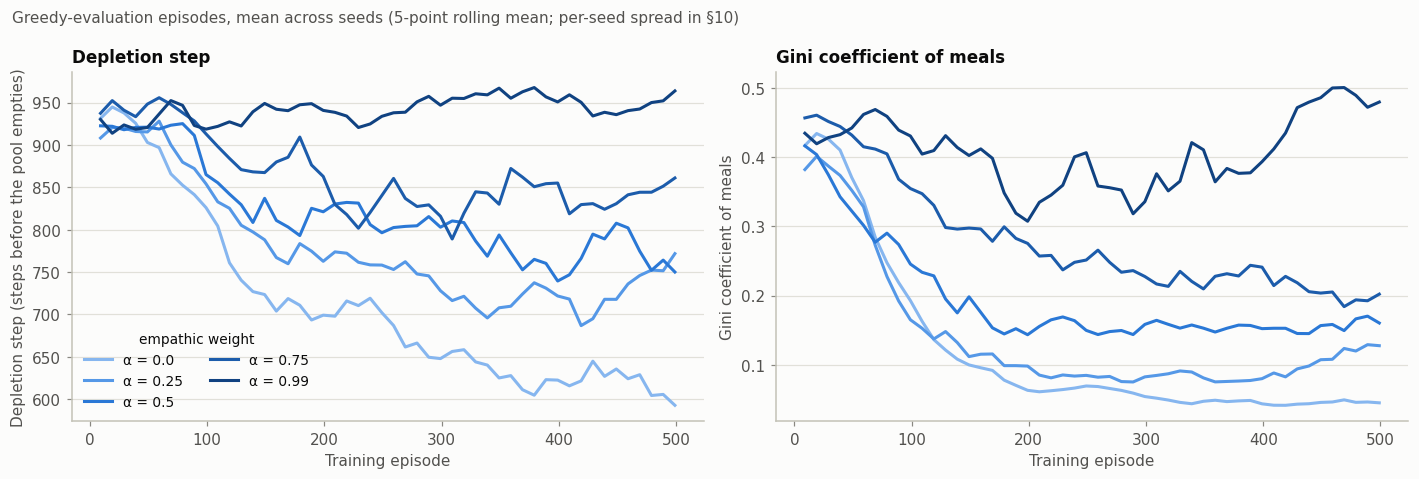

In [9]:
specs = [{"data": ev[ev["alpha"] == a], "color": ALPHA_COLOR[a],
          "label": f"α = {a}"} for a in ALPHAS]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, metric in zip(axes, METRICS):
    # 5 series: CI bands would overlap into an unreadable wash, and the per-seed
    # spread is shown properly in §10.
    learning_curve(ax, metric, specs, show_ci=False)
    ax.set_title(METRIC_LABEL[metric].split(" (")[0])
axes[0].legend(loc="lower left", ncols=2, title="empathic weight",
               title_fontsize=9)
fig.suptitle(f"Greedy-evaluation episodes, mean across seeds "
             f"({SMOOTH_WINDOW}-point rolling mean; per-seed spread in §10)",
             x=0.012, ha="left", color=INK["secondary"], fontsize=10)
fig.tight_layout()
plt.show()


## 7. End-of-training aggregation

The unit of analysis is **one row per (α, seed)**: the mean over the last
`LAST_N_EVAL` greedy evaluation episodes. The seed is the independent
replication — the manuscript's `r_s(18)` came from 20 such points (5 levels ×
4 seeds), and the correlation below is computed the same way.

In [10]:
GROUP_KEYS = ["condition", "alpha"]
seed_df = end_of_training(ev, GROUP_KEYS).sort_values(["alpha", "seed"])

print(f"{len(seed_df)} seed-level rows "
      f"({seed_df['n_eval'].min()}-{seed_df['n_eval'].max()} eval episodes each, "
      f"episodes {seed_df['from_episode'].min()}-{seed_df['to_episode'].max()})")
display(seed_df.reset_index(drop=True))


50 seed-level rows (10-10 eval episodes each, episodes 409-499)


,condition,alpha,seed,depletion_step,gini_meals,total_meals,censored_frac,n_eval,from_episode,to_episode
0,alpha000_res,0.00,1,617.3,0.040107,499.9,0.1,10,409,499
1,alpha000_res,0.00,2,621.7,0.044533,500.0,0.0,10,409,499
2,alpha000_res,0.00,7,639.5,0.046637,499.9,0.1,10,409,499
3,alpha000_res,0.00,11,597.1,0.054133,500.0,0.0,10,409,499
4,alpha000_res,0.00,12,613.6,0.050400,500.0,0.0,10,409,499
5,alpha000_res,0.00,13,641.7,0.043600,500.0,0.0,10,409,499
6,alpha000_res,0.00,14,739.6,0.048667,500.0,0.0,10,409,499
7,alpha000_res,0.00,15,543.0,0.038933,500.0,0.0,10,409,499
8,alpha000_res,0.00,16,562.2,0.034200,500.0,0.0,10,409,499
9,alpha000_res,0.00,17,670.6,0.045333,500.0,0.0,10,409,499


In [11]:
summary = describe_groups(seed_df, "alpha")
display(summary.style.format({c: "{:.3f}" for c in summary.columns
                              if summary[c].dtype.kind == "f"}))


,alpha,n_seeds,depletion_step_mean,depletion_step_ci95,depletion_step_sd,gini_meals_mean,gini_meals_ci95,gini_meals_sd
0,0.000,10,624.630,39.432,55.123,0.045,0.004,0.006
1,0.250,10,723.690,43.635,60.998,0.107,0.026,0.037
2,0.500,10,773.430,40.056,55.994,0.156,0.037,0.052
3,0.750,10,837.540,33.764,47.199,0.206,0.046,0.064
4,0.990,10,942.180,20.946,29.281,0.480,0.059,0.083


## 8. Dose-response: Spearman correlations

The manuscript's headline statistic. α is treated as a numeric level and each
(α, seed) point is one observation, so `n` is the number of seed-level rows and
`df = n − 2`.

Pearson is reported alongside only to show whether the relation is monotone but
non-linear; **Spearman is the test of record**, as in the manuscript.

In [12]:
rows = []
for metric in METRICS + ["total_meals"]:
    rho, p_s = stats.spearmanr(seed_df["alpha"], seed_df[metric])
    lo, hi = spearman_ci(rho, len(seed_df))
    r, p_p = stats.pearsonr(seed_df["alpha"], seed_df[metric])
    rows.append({"metric": METRIC_LABEL[metric].split(" (")[0],
                 "n": len(seed_df), "df": len(seed_df) - 2,
                 "spearman_rho": rho, "rho_lo95": lo, "rho_hi95": hi,
                 "p_spearman": p_s, "sig": stars(p_s),
                 "pearson_r": r, "p_pearson": p_p})
correlations = pd.DataFrame(rows)
display(correlations.style.format({"spearman_rho": "{:+.3f}", "rho_lo95": "{:+.3f}",
                                   "rho_hi95": "{:+.3f}", "p_spearman": "{:.4g}",
                                   "pearson_r": "{:+.3f}", "p_pearson": "{:.4g}"},
                                  na_rep="—"))

PAPER = {"Depletion step": 0.92, "Gini coefficient of meals": 0.96}
print("Manuscript (4 seeds/level, no r_t, biased training):")
for name, paper_rho in PAPER.items():
    got = correlations.loc[correlations["metric"] == name, "spearman_rho"].iloc[0]
    print(f"  {name:<28} paper r_s = {paper_rho:+.2f}   this re-run r_s = {got:+.3f}")


,metric,n,df,spearman_rho,rho_lo95,rho_hi95,p_spearman,sig,pearson_r,p_pearson
0,Depletion step,50,48,+0.905,+0.821,+0.951,1.9e-19,***,+0.903,2.87e-19
1,Gini coefficient of meals,50,48,+0.917,+0.843,+0.957,7.998e-21,***,+0.859,1.569e-15
2,Total meals consumed per episode,50,48,-0.804,-0.893,-0.653,2.076e-12,***,-0.569,1.654e-05


Manuscript (4 seeds/level, no r_t, biased training):
  Depletion step               paper r_s = +0.92   this re-run r_s = +0.905
  Gini coefficient of meals    paper r_s = +0.96   this re-run r_s = +0.917


## 9. Ordered trend and level-by-level tests

Kruskal–Wallis ignores the ordering of α; the **Jonckheere–Terpstra** test uses
it and is therefore the appropriate rank test for a dose-response claim. The
one-way ANOVA plus Tukey HSD is the parametric counterpart, and the pairwise
Mann–Whitney table with Holm correction shows *where* along the α axis the
levels actually separate.

In [13]:
for metric in METRICS:
    groups = [seed_df.loc[seed_df["alpha"] == a, metric].to_numpy() for a in ALPHAS]
    h, p_kw = stats.kruskal(*groups)
    jt, z, p_jt = jonckheere_terpstra(groups)
    model = ols(f"{metric} ~ C(alpha)", data=seed_df).fit()
    aov = anova_lm(model, typ=2)
    aov["partial_eta_sq"] = aov["sum_sq"] / (aov["sum_sq"] + aov.loc["Residual", "sum_sq"])
    aov.loc["Residual", "partial_eta_sq"] = np.nan

    print("=" * 78)
    print(f"{METRIC_LABEL[metric]}   (n = {len(seed_df)} seeds, "
          f"{len(seed_df) // len(ALPHAS)} per level)")
    print("=" * 78)
    print(f"Kruskal-Wallis      H = {h:.3f}, p = {p_kw:.4g} {stars(p_kw)}   "
          f"(ignores the order of α)")
    print(f"Jonckheere-Terpstra JT = {jt:.1f}, z = {z:+.3f}, p = {p_jt:.4g} "
          f"{stars(p_jt)}   (ordered alternative)")
    display(aov.style.format({"sum_sq": "{:.4g}", "F": "{:.3f}", "PR(>F)": "{:.4g}",
                              "partial_eta_sq": "{:.3f}"}, na_rep="—"))
    display(assumption_checks(model.resid, groups)
            .style.format({"statistic": "{:.3f}", "p": "{:.4f}"}))


Depletion step (steps before the pool empties)   (n = 50 seeds, 10 per level)
Kruskal-Wallis      H = 40.356, p = 3.654e-08 ***   (ignores the order of α)
Jonckheere-Terpstra JT = 928.5, z = +7.331, p = 2.288e-13 ***   (ordered alternative)


,sum_sq,df,F,PR(>F),partial_eta_sq
C(alpha),5.697e+05,4.000000,54.861,9.741e-17,0.830
Residual,1.168e+05,45.000000,—,—,—


,test,statistic,p,verdict
0,Shapiro-Wilk (residual normality),0.987,0.8543,ok
1,Levene (homoscedasticity),0.622,0.6493,ok


Gini coefficient of meals   (n = 50 seeds, 10 per level)
Kruskal-Wallis      H = 41.923, p = 1.731e-08 ***   (ignores the order of α)
Jonckheere-Terpstra JT = 941.0, z = +7.545, p = 4.536e-14 ***   (ordered alternative)


,sum_sq,df,F,PR(>F),partial_eta_sq
C(alpha),1.132,4.000000,94.283,2.812e-21,0.893
Residual,0.1351,45.000000,—,—,—


,test,statistic,p,verdict
0,Shapiro-Wilk (residual normality),0.932,0.0068,violated -> read the rank test
1,Levene (homoscedasticity),2.055,0.1027,ok


In [14]:
for metric in METRICS:
    print("=" * 78)
    print(f"Tukey HSD — {METRIC_LABEL[metric]}")
    print(pairwise_tukeyhsd(seed_df[metric], seed_df["alpha"], alpha=ALPHA_LEVEL))
    display(pairwise_ranktests(seed_df, metric, "alpha", ALPHAS)
            .style.format({"U": "{:.1f}", "p_raw": "{:.4f}", "p_holm": "{:.4f}",
                           "mean_diff": "{:.3f}", "hedges_g": "{:.2f}",
                           "g_lo": "{:.2f}", "g_hi": "{:.2f}"}))


Tukey HSD — Depletion step (steps before the pool empties)
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
   0.0   0.25    99.06 0.0007  34.3155 163.8045   True
   0.0    0.5    148.8    0.0  84.0555 213.5445   True
   0.0   0.75   212.91    0.0 148.1655 277.6545   True
   0.0   0.99   317.55    0.0 252.8055 382.2945   True
  0.25    0.5    49.74 0.2048 -15.0045 114.4845  False
  0.25   0.75   113.85 0.0001  49.1055 178.5945   True
  0.25   0.99   218.49    0.0 153.7455 283.2345   True
   0.5   0.75    64.11 0.0534  -0.6345 128.8545  False
   0.5   0.99   168.75    0.0 104.0055 233.4945   True
  0.75   0.99   104.64 0.0003  39.8955 169.3845   True
------------------------------------------------------


,pair,U,p_raw,mean_diff,hedges_g,g_lo,g_hi,p_holm,sig
0,0.0 vs 0.25,15.0,0.0091,-99.060,-1.63,-2.66,-0.61,0.0273,*
1,0.0 vs 0.5,2.0,0.0003,-148.800,-2.57,-3.78,-1.35,0.0020,**
2,0.0 vs 0.75,0.0,0.0002,-212.910,-3.97,-5.54,-2.41,0.0018,**
3,0.0 vs 0.99,0.0,0.0002,-317.550,-6.89,-9.31,-4.48,0.0018,**
4,0.25 vs 0.5,27.5,0.0962,-49.740,-0.81,-1.73,0.10,0.0962,ns
5,0.25 vs 0.75,3.0,0.0004,-113.850,-2.00,-3.09,-0.91,0.0022,**
6,0.25 vs 0.99,0.0,0.0002,-218.490,-4.37,-6.05,-2.70,0.0018,**
7,0.5 vs 0.75,21.0,0.0312,-64.110,-1.19,-2.14,-0.23,0.0624,ns
8,0.5 vs 0.99,0.0,0.0002,-168.750,-3.62,-5.09,-2.15,0.0018,**
9,0.75 vs 0.99,3.0,0.0004,-104.640,-2.55,-3.76,-1.34,0.0022,**


Tukey HSD — Gini coefficient of meals
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
   0.0   0.25   0.0625 0.0975 -0.0071 0.1321  False
   0.0    0.5   0.1112 0.0004  0.0416 0.1808   True
   0.0   0.75   0.1615    0.0  0.0919 0.2312   True
   0.0   0.99   0.4354    0.0  0.3658 0.5051   True
  0.25    0.5   0.0487 0.2879 -0.0209 0.1183  False
  0.25   0.75   0.0991 0.0018  0.0294 0.1687   True
  0.25   0.99    0.373    0.0  0.3033 0.4426   True
   0.5   0.75   0.0503 0.2577 -0.0193 0.1199  False
   0.5   0.99   0.3242    0.0  0.2546 0.3939   True
  0.75   0.99   0.2739    0.0  0.2043 0.3435   True
---------------------------------------------------


,pair,U,p_raw,mean_diff,hedges_g,g_lo,g_hi,p_holm,sig
0,0.0 vs 0.25,0.0,0.0002,-0.062,-2.28,-3.43,-1.13,0.0018,**
1,0.0 vs 0.5,0.0,0.0002,-0.111,-2.88,-4.17,-1.60,0.0018,**
2,0.0 vs 0.75,0.0,0.0002,-0.162,-3.40,-4.81,-1.99,0.0018,**
3,0.0 vs 0.99,0.0,0.0002,-0.435,-7.12,-9.61,-4.63,0.0018,**
4,0.25 vs 0.5,22.0,0.0376,-0.049,-1.04,-1.98,-0.10,0.0753,ns
5,0.25 vs 0.75,5.0,0.0008,-0.099,-1.82,-2.88,-0.76,0.0023,**
6,0.25 vs 0.99,0.0,0.0002,-0.373,-5.59,-7.62,-3.56,0.0018,**
7,0.5 vs 0.75,30.0,0.1405,-0.050,-0.83,-1.74,0.09,0.1405,ns
8,0.5 vs 0.99,0.0,0.0002,-0.324,-4.50,-6.21,-2.79,0.0018,**
9,0.75 vs 0.99,2.0,0.0003,-0.274,-3.55,-5.00,-2.09,0.0018,**


## 10. Figures

Left: the dose-response itself — every seed as a point, the level means with
95% CIs, and an ordinary-least-squares trend line. Right: the same data as
boxplots so the within-level spread is visible.

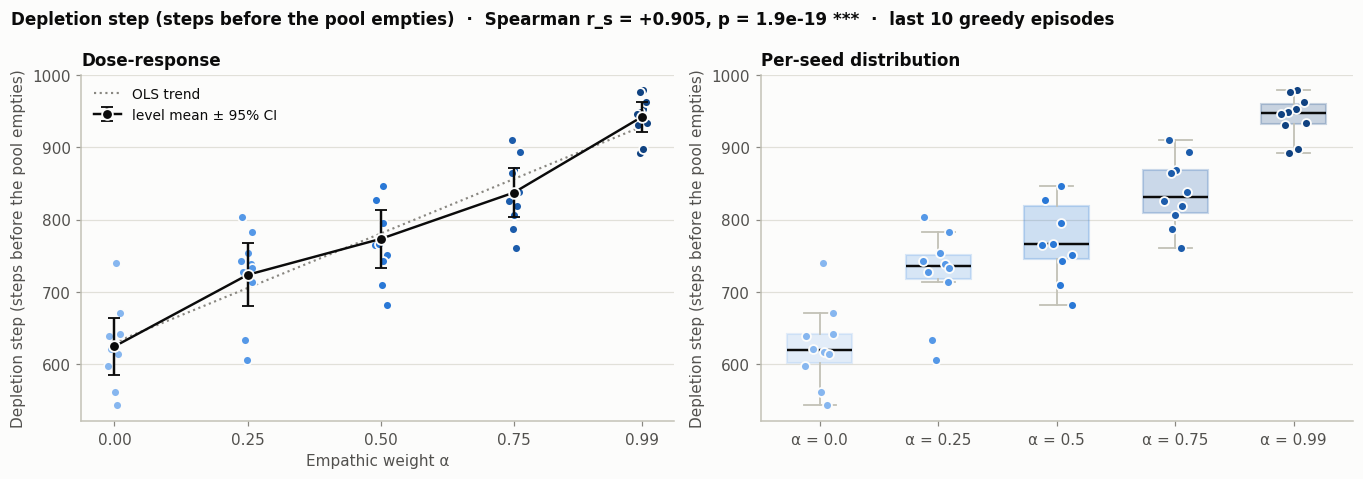

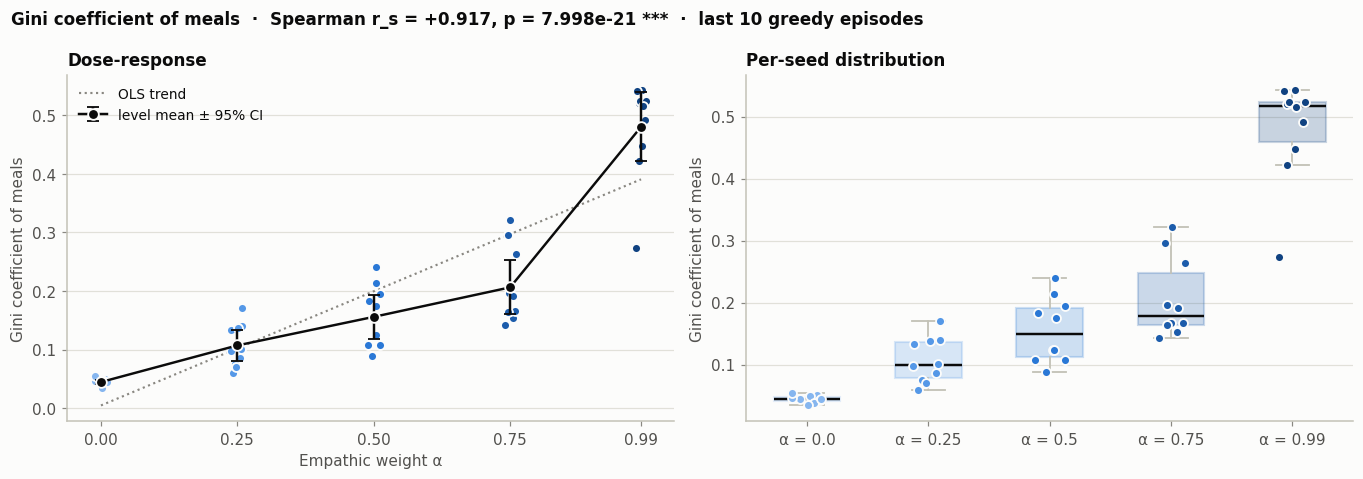

In [15]:
def dose_response(ax, data, metric):
    rng = np.random.default_rng(0)
    for a in ALPHAS:
        vals = data.loc[data["alpha"] == a, metric].to_numpy()
        ax.scatter(a + rng.uniform(-0.012, 0.012, len(vals)), vals, s=34,
                   color=ALPHA_COLOR[a], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    means = [mean_ci(data.loc[data["alpha"] == a, metric]) for a in ALPHAS]
    ax.errorbar(ALPHAS, [m for m, _ in means], yerr=[h for _, h in means],
                color=INK["primary"], lw=1.6, marker="o", ms=7, capsize=4,
                mec=SURFACE, mew=1.2, zorder=4, label="level mean ± 95% CI")
    slope, intercept = np.polyfit(data["alpha"], data[metric], 1)
    xs = np.linspace(min(ALPHAS), max(ALPHAS), 50)
    ax.plot(xs, intercept + slope * xs, color=INK["muted"], lw=1.4, ls=":",
            zorder=2, label="OLS trend")
    ax.set_xlabel("Empathic weight α")
    ax.set_ylabel(METRIC_LABEL[metric])
    ax.set_xticks(ALPHAS)


for metric in METRICS:
    rho = correlations.loc[correlations["metric"] == METRIC_LABEL[metric].split(" (")[0],
                           "spearman_rho"].iloc[0]
    p_s = correlations.loc[correlations["metric"] == METRIC_LABEL[metric].split(" (")[0],
                           "p_spearman"].iloc[0]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
    dose_response(axes[0], seed_df, metric)
    axes[0].set_title("Dose-response")
    axes[0].legend(loc="best")
    box_strip(axes[1], seed_df, metric, "alpha", ALPHAS,
              [ALPHA_COLOR[a] for a in ALPHAS], [f"α = {a}" for a in ALPHAS])
    axes[1].set_title("Per-seed distribution")
    fig.suptitle(f"{METRIC_LABEL[metric]}  ·  Spearman r_s = {rho:+.3f}, "
                 f"p = {p_s:.4g} {stars(p_s)}  ·  last {LAST_N_EVAL} greedy episodes",
                 x=0.012, ha="left", fontsize=11, fontweight="semibold")
    fig.tight_layout()
    plt.show()


## 11. The α = 0.99 caveat

At α ≈ 1 the personal term of the reward `r_i = (1−α)·personal + α·empathic` is
almost extinguished, so a long-lived pool at that level may simply mean the
agents were never given a reason to consume, rather than that they learned a
sustainable policy. The tracker flags this explicitly and would settle it against
the `always_abstain` baseline — which has not been run.

**Total meals consumed** separates the two readings without that baseline: a
sustainable policy still feeds the agents (consumption is spread out), whereas
extinguished incentive means near-zero consumption. The pool holds
`initial_resources` units, so the maximum meals an episode could deliver is
bounded by it.

In [16]:
consumption = (seed_df.groupby("alpha", observed=True)
                      .agg(n_seeds=("seed", "size"),
                           total_meals=("total_meals", "mean"),
                           depletion_step=("depletion_step", "mean"),
                           censored_frac=("censored_frac", "mean"))
                      .reset_index())
consumption["meals_per_step"] = consumption["total_meals"] / consumption["depletion_step"]
consumption["pct_of_alpha0_meals"] = (consumption["total_meals"]
                                      / consumption["total_meals"].iloc[0])
display(consumption.style.format({"total_meals": "{:.1f}", "depletion_step": "{:.1f}",
                                  "meals_per_step": "{:.3f}", "censored_frac": "{:.1%}",
                                  "pct_of_alpha0_meals": "{:.1%}"}))

top, base = consumption.iloc[-1], consumption.iloc[0]
ratio = top["total_meals"] / base["total_meals"]
print(f"At α = {top['alpha']}, agents still eat {ratio:.0%} of what they eat at "
      f"α = {base['alpha']} ({top['total_meals']:.0f} vs {base['total_meals']:.0f} "
      f"meals per episode).")
if ratio < 0.25:
    print("  -> consumption has largely collapsed: the apparent sustainability at high α "
          "is consistent with the incentive to consume being extinguished, NOT with a "
          "learned sustainable policy. Run the always_abstain baseline before "
          "interpreting the dose-response at the top of the range.")
else:
    print("  -> agents keep consuming substantially at high α, so the longer resource "
          "lifetime is not merely an extinguished incentive to eat.")
print(f"Censoring rises from {base['censored_frac']:.0%} at α = {base['alpha']} to "
      f"{top['censored_frac']:.0%} at α = {top['alpha']}: the depletion step is "
      f"censored preferentially in the conditions the trend predicts to be highest, "
      f"which BIASES the correlation downwards.")


,alpha,n_seeds,total_meals,depletion_step,censored_frac,meals_per_step,pct_of_alpha0_meals
0,0.000000,10,500.0,624.6,2.0%,0.800,100.0%
1,0.250000,10,499.8,723.7,15.0%,0.691,100.0%
2,0.500000,10,499.3,773.4,16.0%,0.646,99.9%
3,0.750000,10,473.0,837.5,32.0%,0.565,94.6%
4,0.990000,10,436.4,942.2,74.0%,0.463,87.3%


At α = 0.99, agents still eat 87% of what they eat at α = 0.0 (436 vs 500 meals per episode).
  -> agents keep consuming substantially at high α, so the longer resource lifetime is not merely an extinguished incentive to eat.
Censoring rises from 2% at α = 0.0 to 74% at α = 0.99: the depletion step is censored preferentially in the conditions the trend predicts to be highest, which BIASES the correlation downwards.


## 12. Read-out

Conclusions are derived from the tables above rather than typed in, so they stay
correct as seeds are added.

In [17]:
print("=" * 78)
print(f"exp3_graded_alpha — {seed_df['seed'].nunique()} seeds total, "
      f"{len(seed_df) // len(ALPHAS)} per α level, last {LAST_N_EVAL} greedy episodes")
print("=" * 78)

TH = {"depletion_step": ("TH3", "resource lifetime increases with α", +1),
      "gini_meals": ("TH4", "inequality DEcreases with α (paper found the opposite)", -1)}

for metric in METRICS:
    name = METRIC_LABEL[metric].split(" (")[0]
    row = correlations.loc[correlations["metric"] == name].iloc[0]
    th, claim, expected_sign = TH[metric]
    means = seed_df.groupby("alpha", observed=True)[metric].mean()
    direction = "increases" if row["spearman_rho"] > 0 else "decreases"
    verdict = ("significant" if row["p_spearman"] < ALPHA_LEVEL else "not significant")
    print(f"\n  {name}  [{th}: {claim}]")
    print(f"    Spearman r_s({row['df']}) = {row['spearman_rho']:+.3f} "
          f"[{row['rho_lo95']:+.3f}, {row['rho_hi95']:+.3f}], "
          f"p = {row['p_spearman']:.4g} -> {verdict}")
    print(f"    the metric {direction} with α: "
          + ", ".join(f"α={a} → {v:.3f}" for a, v in means.items()))
    if row["p_spearman"] < ALPHA_LEVEL:
        matches = np.sign(row["spearman_rho"]) == expected_sign
        print(f"    {th} is {'CONFIRMED' if matches else 'CONTRADICTED'} "
              f"by the sign of the trend.")

print("\n" + "-" * 78)
print("CAVEATS")
print(f"  · {seed_df['seed'].nunique()} seeds (target {TARGET_SEEDS}); "
      f"{len(seed_df) // len(ALPHAS)} per level gives n = {len(seed_df)} correlation "
      f"points against the manuscript's 20.")
print(f"  · {ev['censored'].mean():.1%} of eval episodes hit max_steps with resource "
      f"left, and censoring is concentrated at high α (see §11) — the depletion-step "
      f"correlation is therefore a lower bound on the true trend.")
print(f"  · The α = 0.99 level needs the always_abstain baseline before its "
      f"sustainability can be distinguished from an extinguished incentive to consume "
      f"(§11 gives the consumption-based reading in the meantime).")
print(f"  · Conclusions are read from the last {LAST_N_EVAL} greedy episodes — "
      f"check §6 that the curves had plateaued.")


exp6_graded_alpha — 50 seeds total, 10 per α level, last 10 greedy episodes

  Depletion step  [TH3: resource lifetime increases with α]
    Spearman r_s(48) = +0.905 [+0.821, +0.951], p = 1.9e-19 -> significant
    the metric increases with α: α=0.0 → 624.630, α=0.25 → 723.690, α=0.5 → 773.430, α=0.75 → 837.540, α=0.99 → 942.180
    TH3 is CONFIRMED by the sign of the trend.

  Gini coefficient of meals  [TH4: inequality DEcreases with α (paper found the opposite)]
    Spearman r_s(48) = +0.917 [+0.843, +0.957], p = 7.998e-21 -> significant
    the metric increases with α: α=0.0 → 0.045, α=0.25 → 0.107, α=0.5 → 0.156, α=0.75 → 0.206, α=0.99 → 0.480
    TH4 is CONTRADICTED by the sign of the trend.

------------------------------------------------------------------------------
CAVEATS
  · 50 seeds (target 20); 10 per level gives n = 50 correlation points against the manuscript's 20.
  · 37.0% of eval episodes hit max_steps with resource left, and censoring is concentrated at high α (se

## 13. Manuscript figures (poster style)

The same two metrics as above, re-drawn in the house style used for the LaTeX
figures. Shown inline only — nothing is written to disk.

- **Trajectory** — per-episode mean across seeds over the greedy evaluation
  episodes, with a 95% CI band built from the SEM across seeds and a 5-point
  centred rolling mean.
- **Boxplot** — the seed-level end-of-training values of §7 (one point per seed),
  with pairwise Mann–Whitney U brackets, **Bonferroni**-corrected over the ten
  α pairs. This correction is stricter than the Holm procedure of §9, so a pair
  may carry stars there and not here. α is a categorical axis in these figures;
  the ordered-trend evidence is the Spearman/Jonckheere–Terpstra pair in §8–§9.

Seeds per condition:


,Condition,n_seeds
0,α = 0.00,10
1,α = 0.25,10
2,α = 0.50,10
3,α = 0.75,10
4,α = 0.99,10



===== steps -- layout 'full' =====


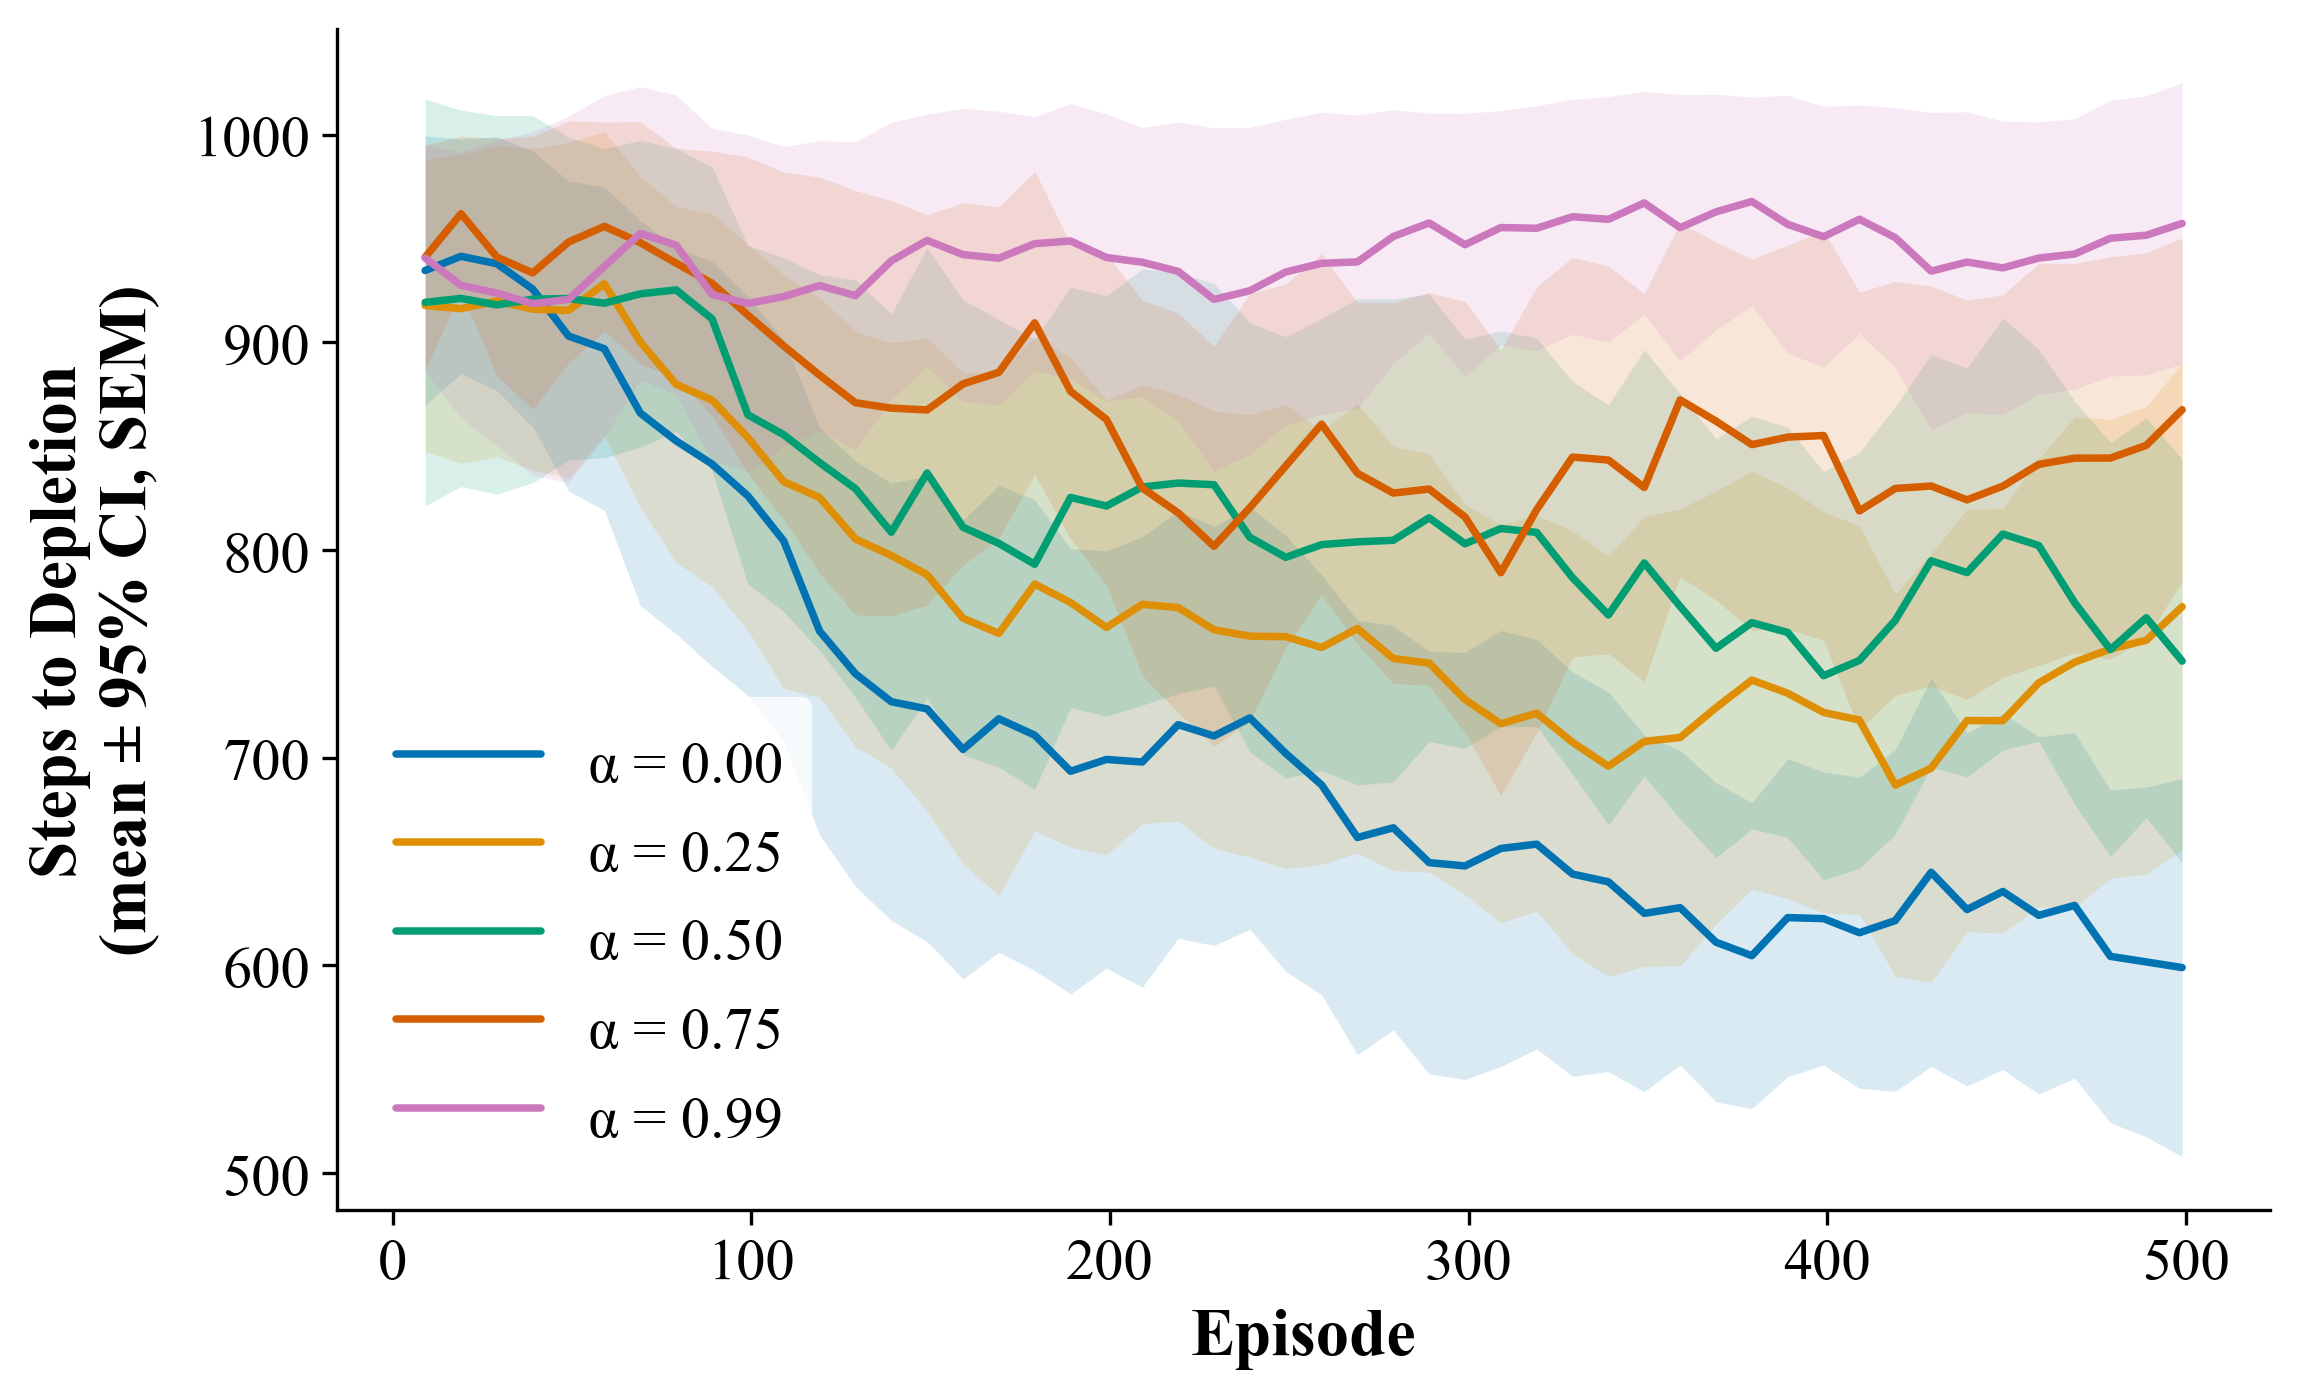


--- Significance tests for depletion_step ---
  α = 0.00 vs α = 0.25: U=15, p=9.1085e-03, p_adj=9.1085e-02  ns
  α = 0.00 vs α = 0.50: U=2, p=3.2984e-04, p_adj=3.2984e-03  **
  α = 0.00 vs α = 0.75: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.00 vs α = 0.99: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.25 vs α = 0.50: U=28, p=9.6179e-02, p_adj=9.6179e-01  ns
  α = 0.25 vs α = 0.75: U=3, p=4.3964e-04, p_adj=4.3964e-03  **
  α = 0.25 vs α = 0.99: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.50 vs α = 0.75: U=21, p=3.1209e-02, p_adj=3.1209e-01  ns
  α = 0.50 vs α = 0.99: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.75 vs α = 0.99: U=3, p=4.3964e-04, p_adj=4.3964e-03  **


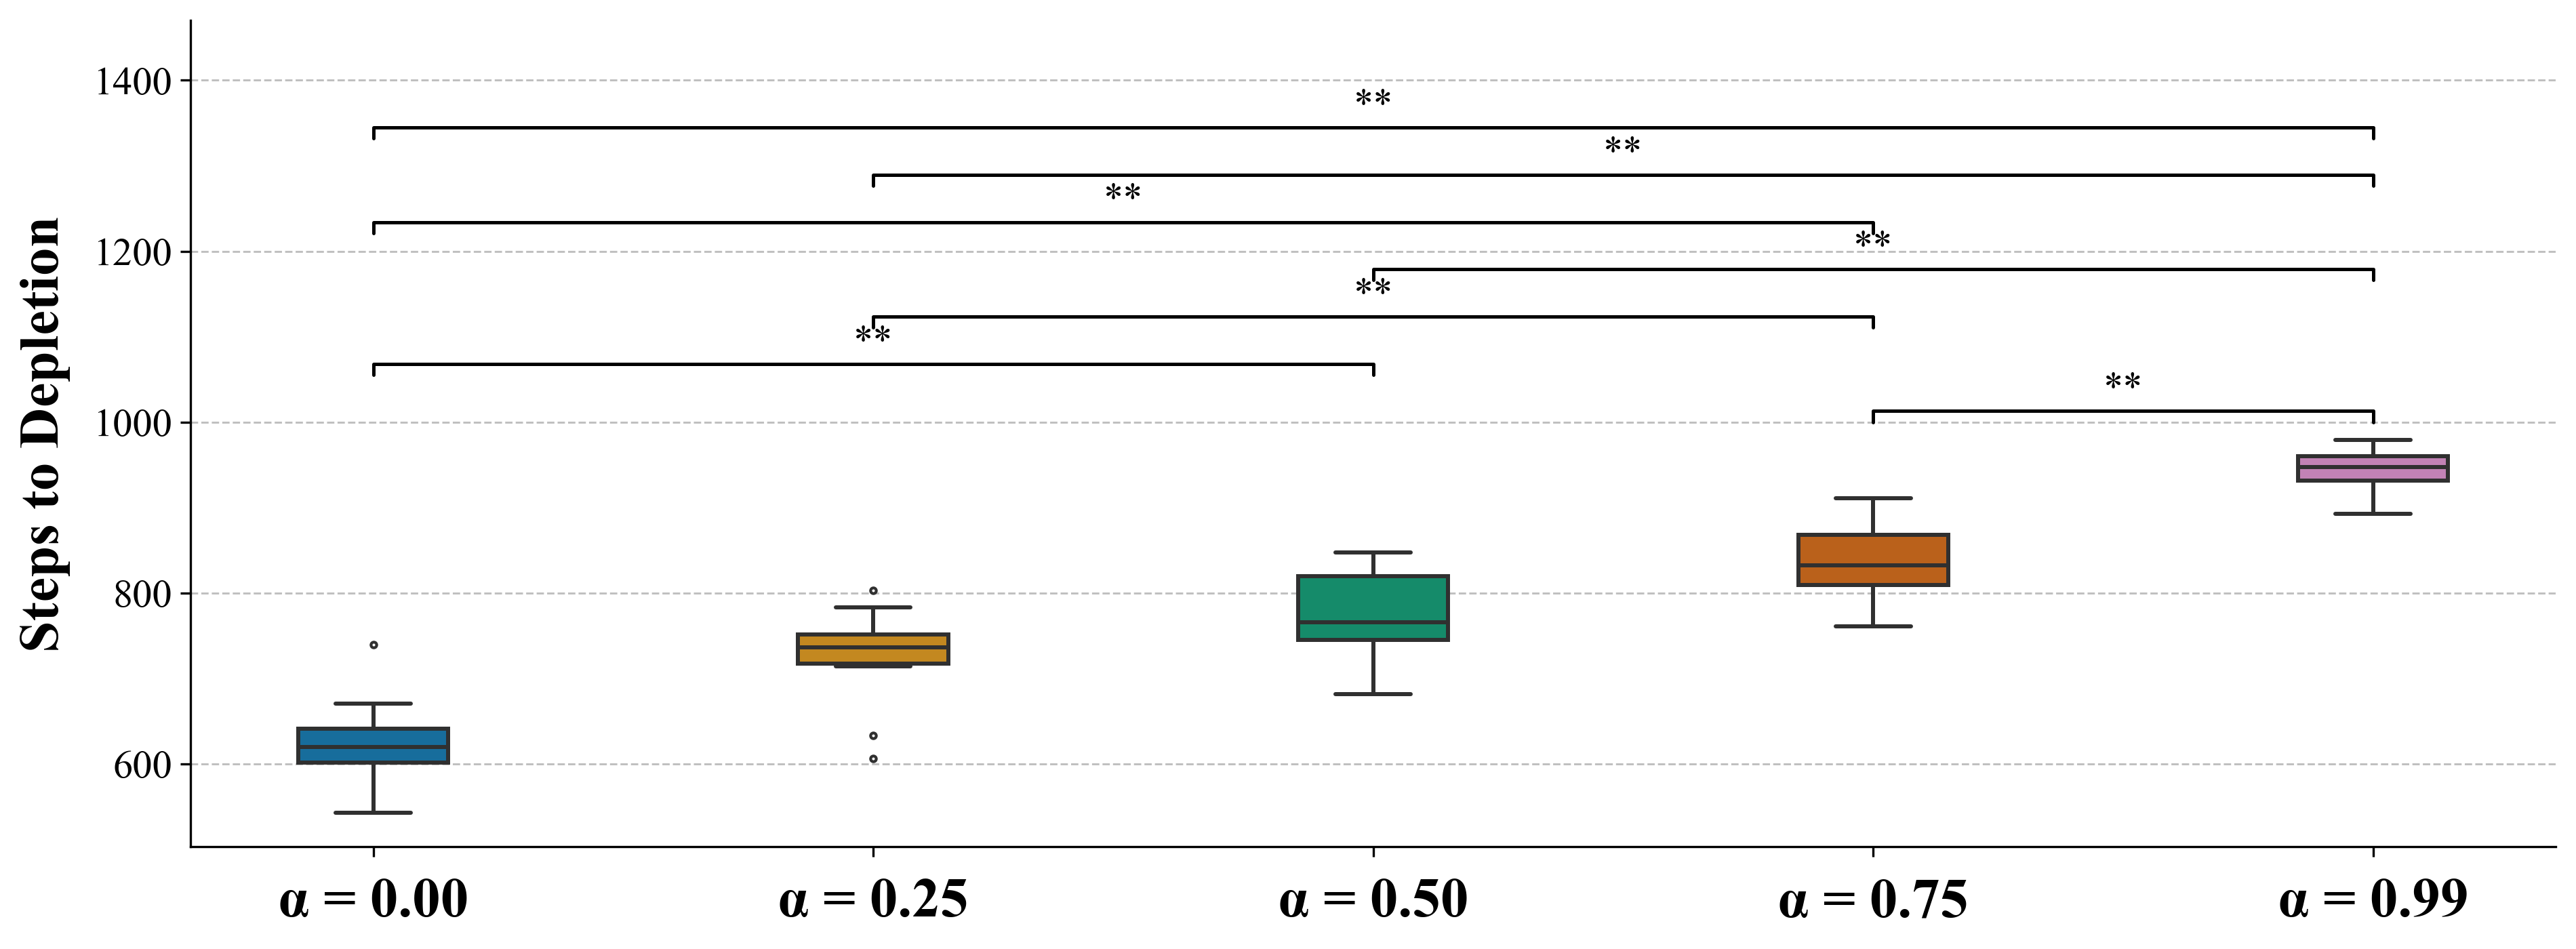


===== steps -- layout '_half' =====


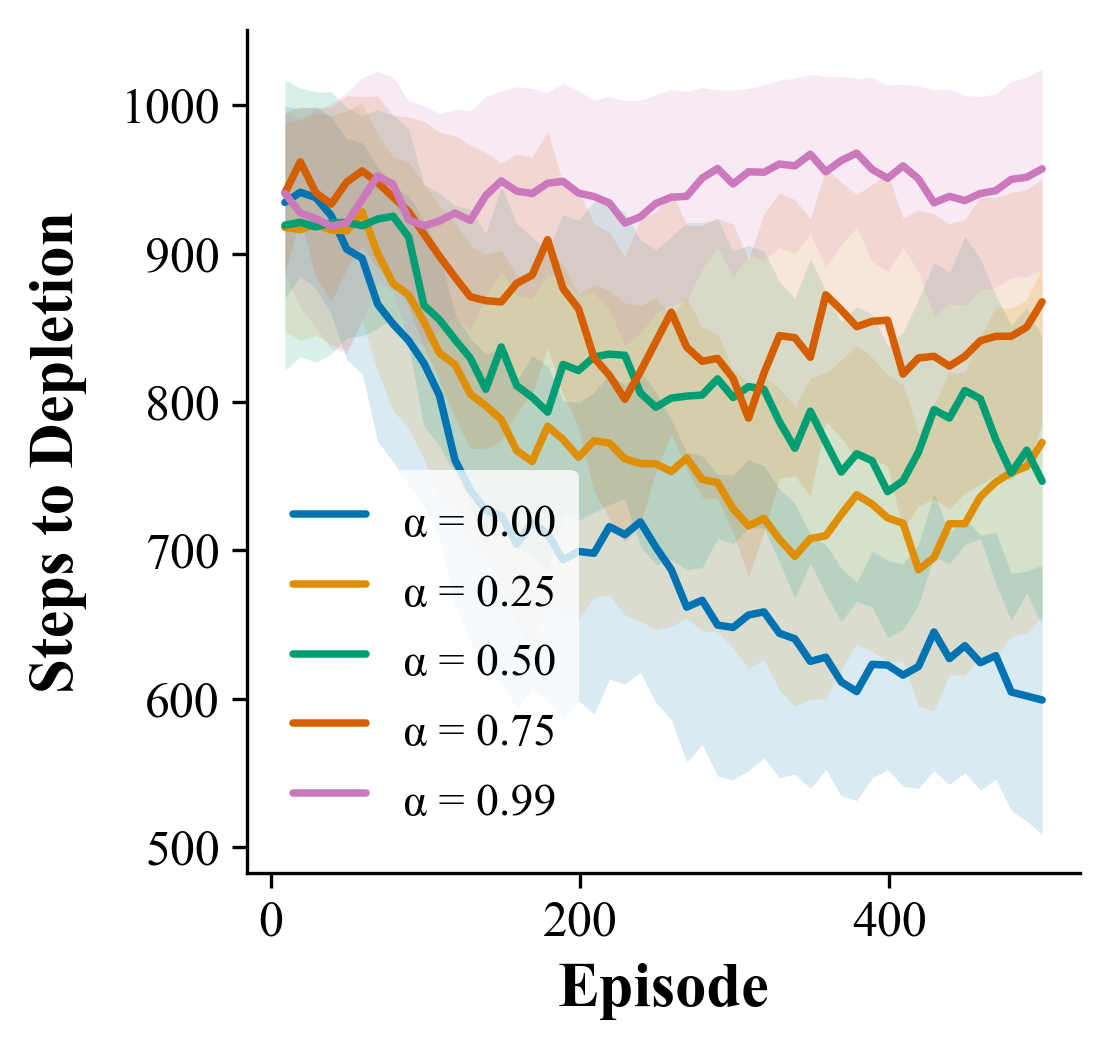

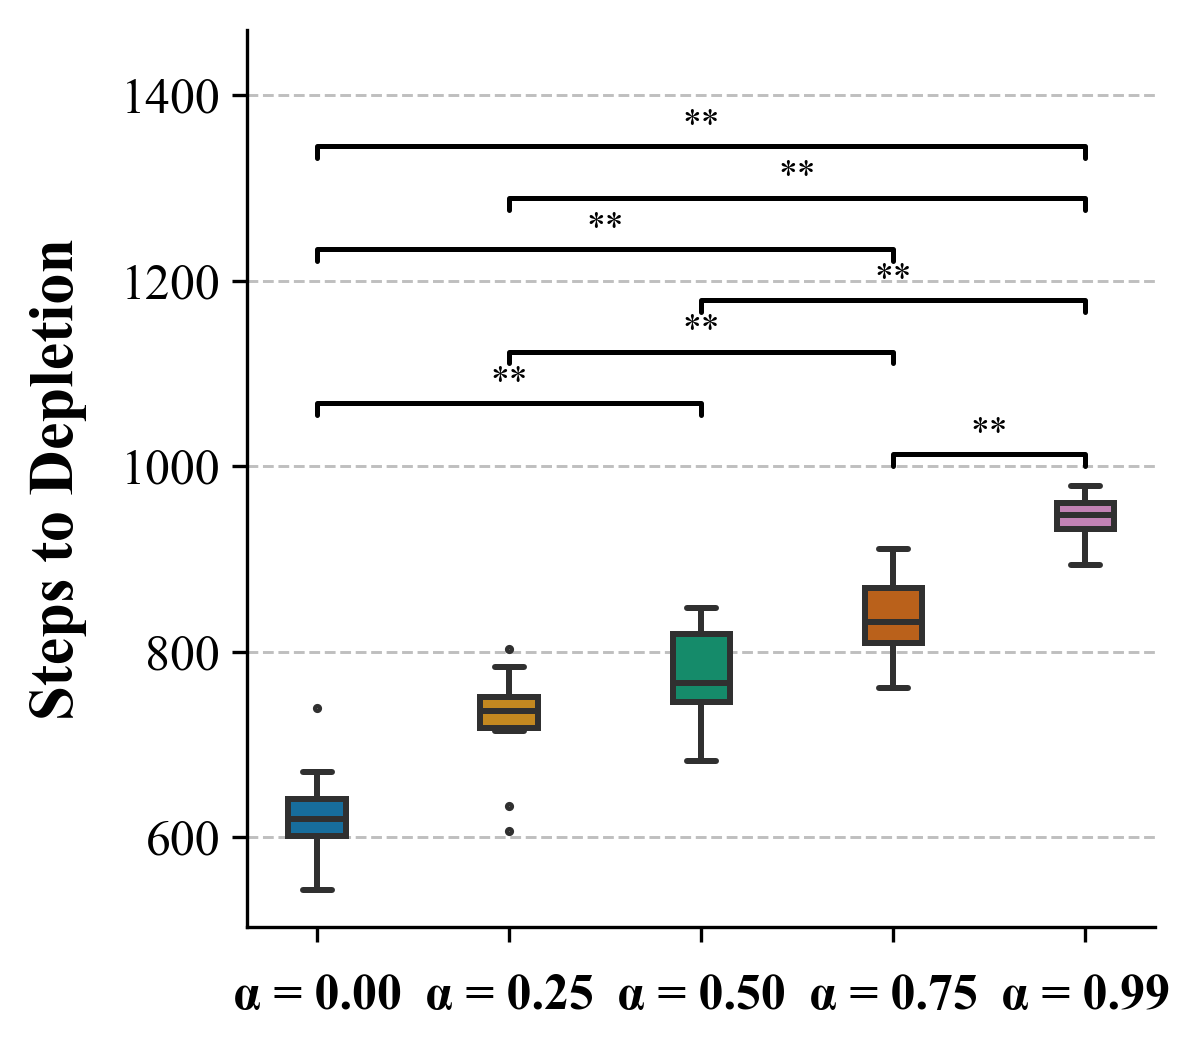


===== gini -- layout 'full' =====


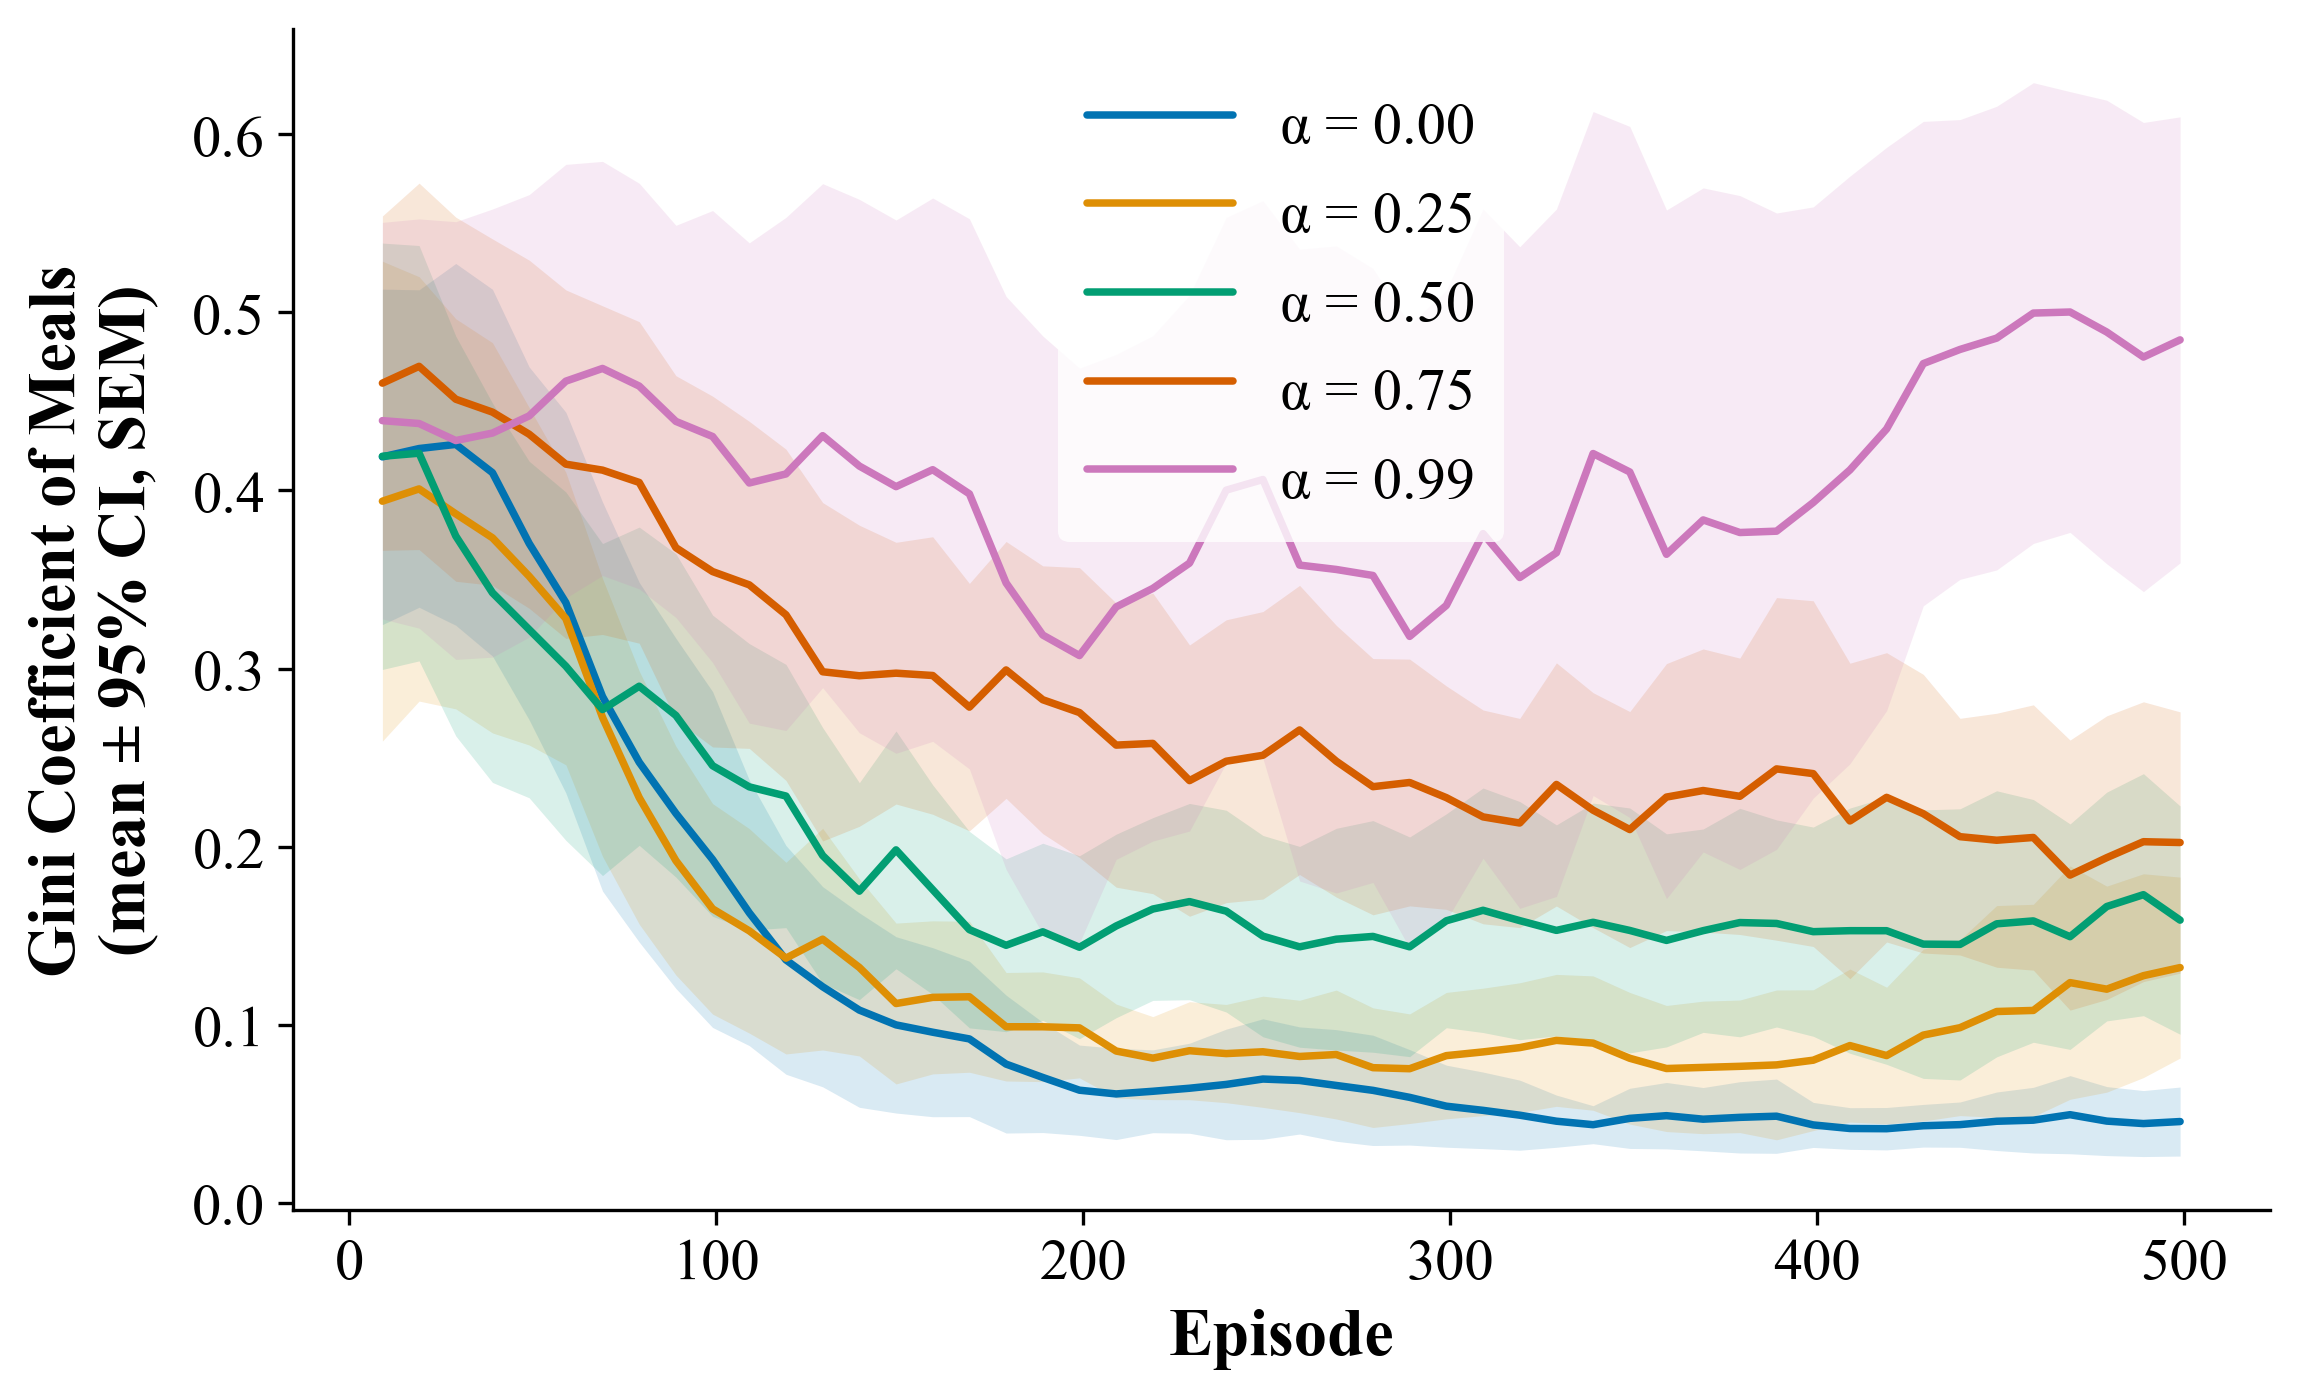


--- Significance tests for gini_meals ---
  α = 0.00 vs α = 0.25: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.00 vs α = 0.50: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.00 vs α = 0.75: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.00 vs α = 0.99: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.25 vs α = 0.50: U=22, p=3.7635e-02, p_adj=3.7635e-01  ns
  α = 0.25 vs α = 0.75: U=5, p=7.6854e-04, p_adj=7.6854e-03  **
  α = 0.25 vs α = 0.99: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.50 vs α = 0.75: U=30, p=1.4047e-01, p_adj=1.0000e+00  ns
  α = 0.50 vs α = 0.99: U=0, p=1.8267e-04, p_adj=1.8267e-03  **
  α = 0.75 vs α = 0.99: U=2, p=3.2984e-04, p_adj=3.2984e-03  **


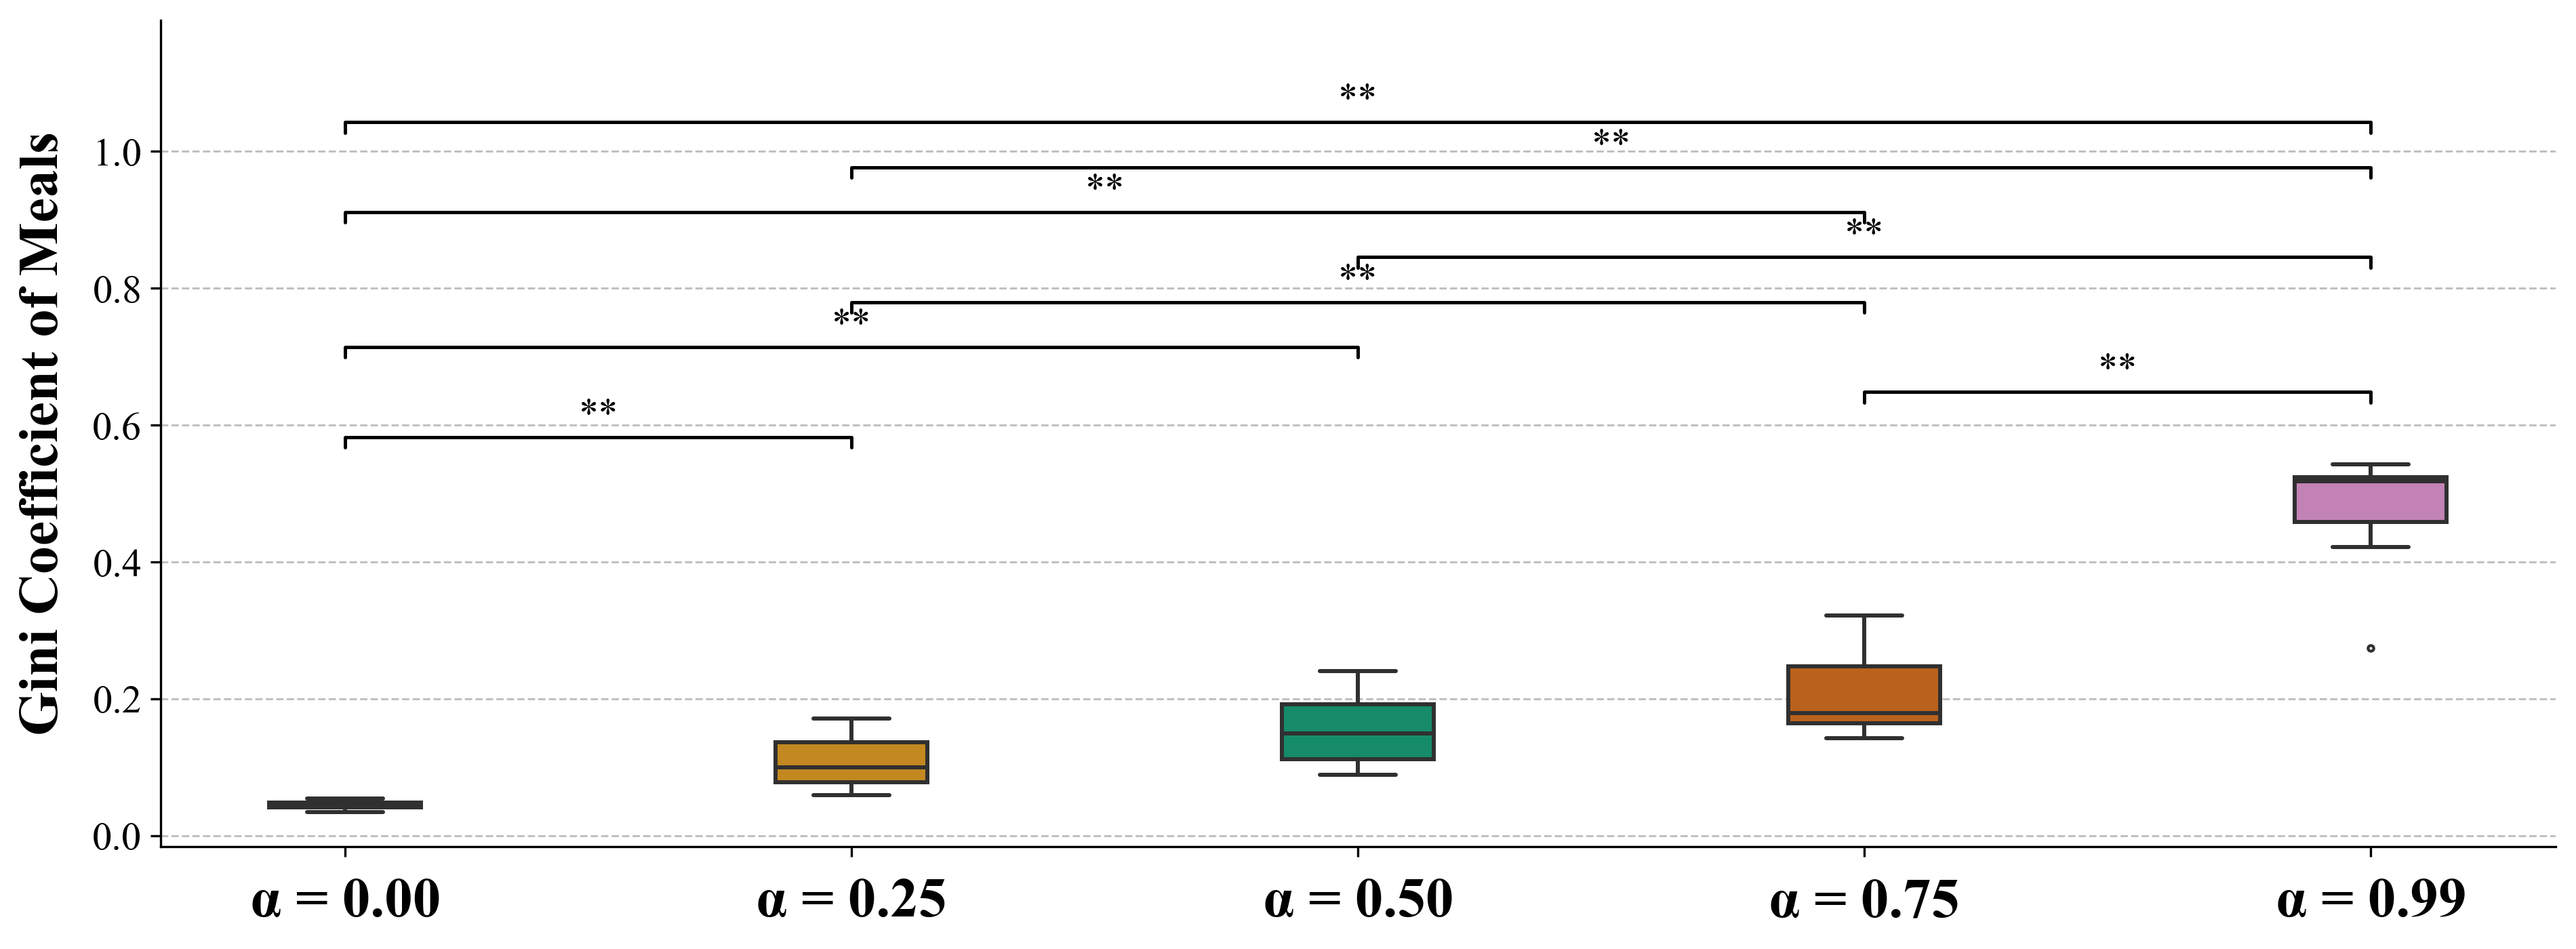


===== gini -- layout '_half' =====


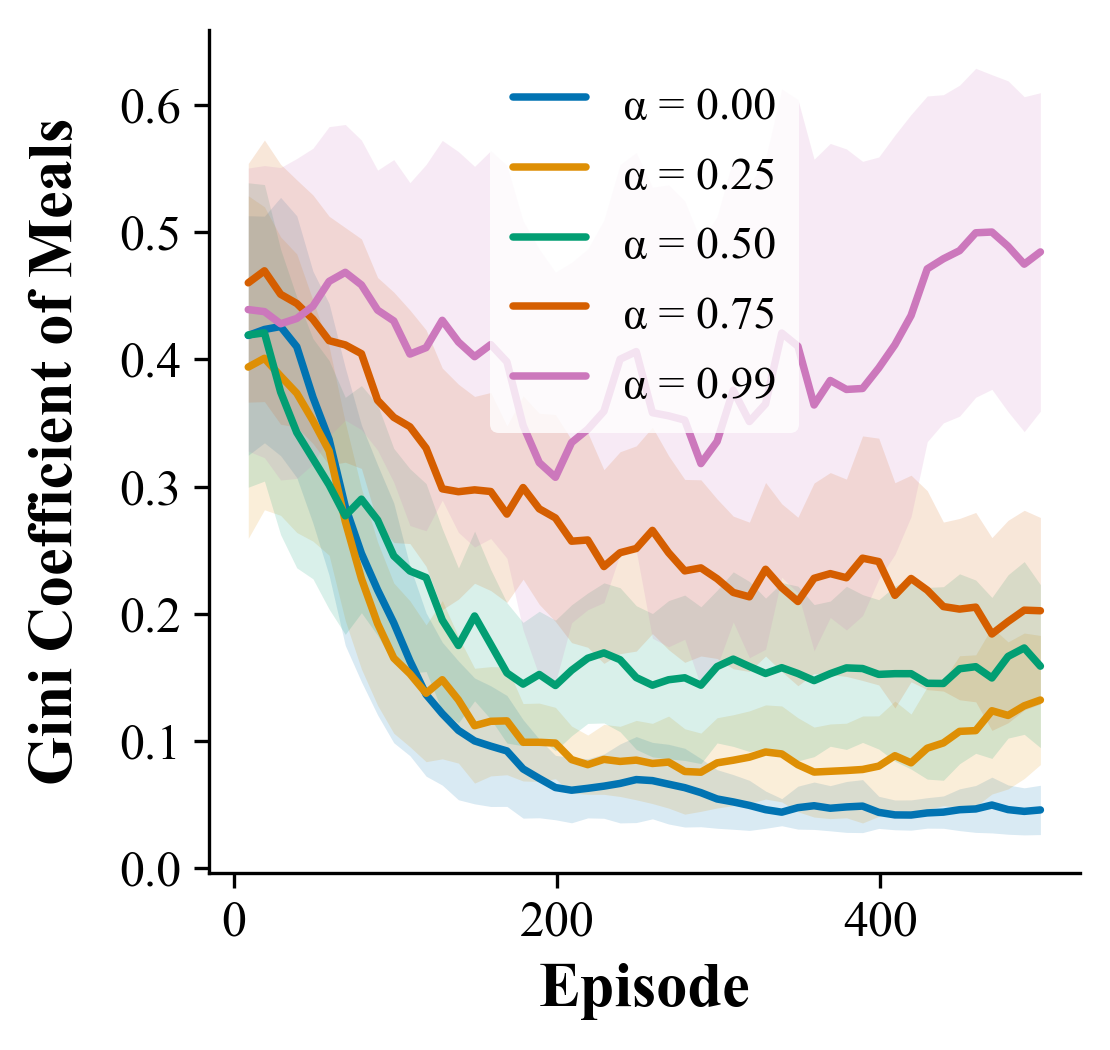

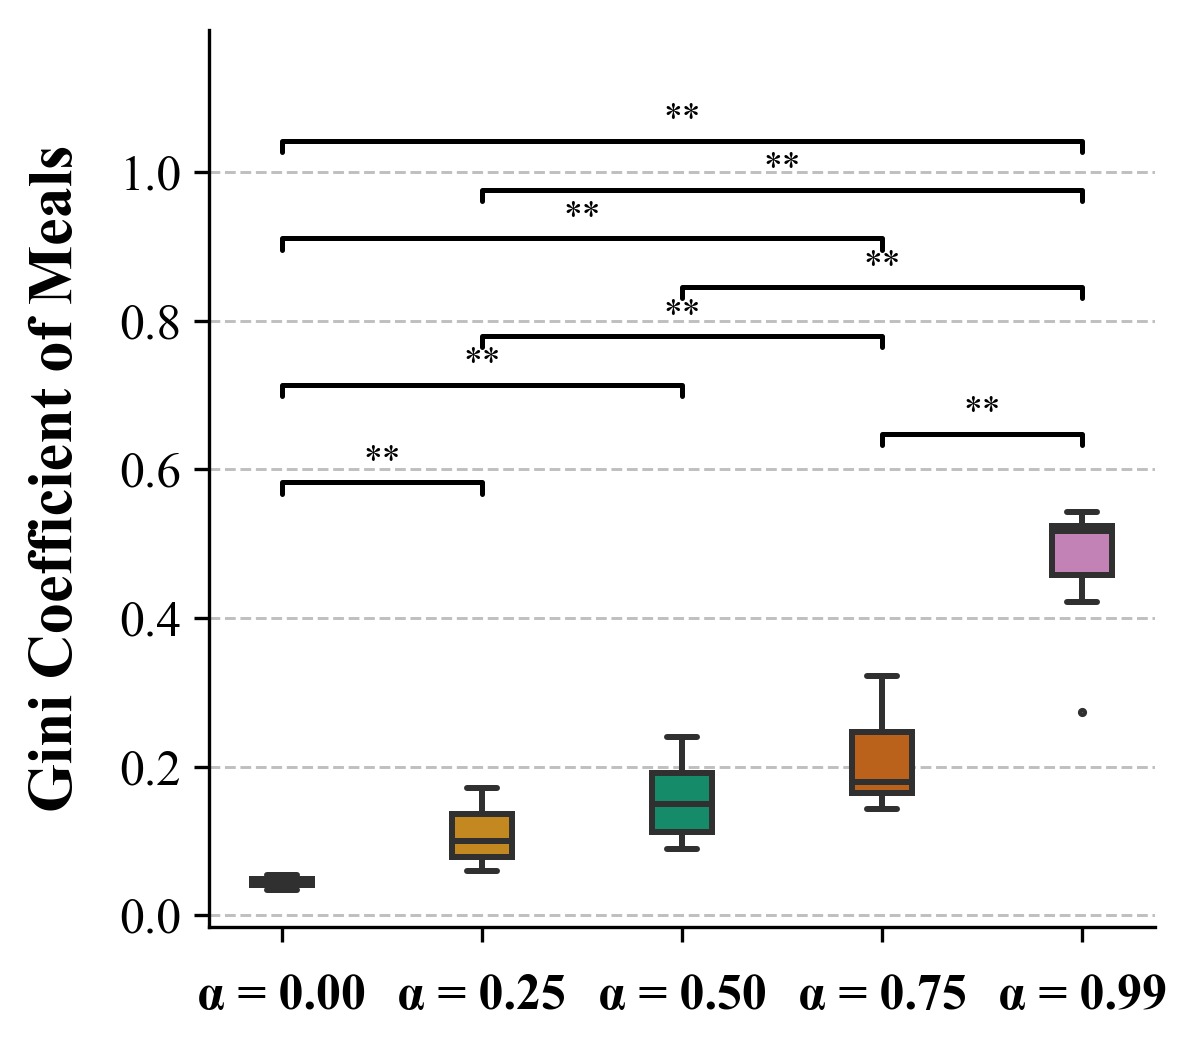

In [18]:
# Poster / manuscript rendering of the two headline metrics. Same numbers as the
# sections above (seed-level means over the last LAST_N_EVAL greedy episodes for
# the boxplots, per-episode means across seeds for the trajectories) -- only the
# house style differs. Figures are shown inline and also written as PDF + PNG
# into FIG_DIR (see below). This cell overwrites the rcParams set in
# section 1, so re-run the
# notebook top-down if the earlier figures are needed again.
from itertools import combinations

import seaborn as sns
from scipy.ndimage import uniform_filter1d
from scipy.stats import norm as _norm, mannwhitneyu

from visualisation_module_test import (
    create_poster_config, apply_style,
    POSTER_BG, POSTER_PALETTE,
)

# -- OUTPUT -------------------------------------------------------------------
# 03_GT figures (journal version). PDF for LaTeX, PNG for slides and quick
# review. Kept inside 03_GT so the AIS 2026 manuscript figures are never
# overwritten.
FIG_DIR = (Path("..") / "figures" / EXPERIMENT).resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIG_PREFIX = "alpha"

def save_fig(fig, name, tight=True):
    # tight=False keeps the canvas at exactly figsize, so the printed aspect
    # ratio is predictable -- required for the side-by-side panels, whose
    # LaTeX widths are computed from it.
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", format=ext,
                    bbox_inches="tight" if tight else None, dpi=300,
                    facecolor=fig.get_facecolor())

# -- CONFIG -------------------------------------------------------------------
config = create_poster_config()
config.label_fontsize = config.label_size = 16
config.tick_fontsize  = config.tick_size  = 14
config.legend_fontsize = config.legend_size = 14
apply_style(config)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif":  ["Times New Roman"],
    "axes.edgecolor":  "black",
    "axes.labelcolor": "black",
    "xtick.color":     "black",
    "ytick.color":     "black",
    "text.color":      "black",
})

BOX_WIDTH  = 0.30

# Two renderings of the same figures:
#   ""      full-width poster / manuscript version (geometry unchanged)
#   "_half" sized for the side-by-side (a)/(b) layout in Results.tex, where the
#           panels are printed at 0.37 and 0.60 of the 12.2 cm LNCS text width.
#           Halving the canvas takes the print reduction from ~23% to ~49%, so
#           labels land near 8 pt instead of the 4 pt of the full-size files.
LAYOUTS = {
    "": dict(fig_w=8.0, fig_h=5.0, fig_w_box=13.0,
             label_fs=16, tick_fs=14, legend_fs=14, legend_ncol=1, handlelen=2.5,
             box_label_fs=20, box_tick_fs=20, star_fs=14,
             line_w=None, flier=2.0, pad=0.8,
             ci_in_ylabel=True, short_labels=False, tight=True),
    # The boxplot goes from 13:5 to a near-square canvas: at half width a
    # 2.7 aspect leaves a 2.9 cm-tall panel, too flat for the bracket stack.
    # Results.tex shows a single figure row per study, so the panels can be
    # taller than wide: they print ~5.4 cm high on the 12.2 cm LNCS line.
    # Condition names move to the caption/legend, so the x-axis keeps only
    # the short label, and the CI note leaves the y-label (it is in the
    # LaTeX caption already).
    "_half": dict(fig_w=3.6, fig_h=3.4, fig_w_box=3.9,
                  label_fs=15, tick_fs=12, legend_fs=11, legend_ncol=1, handlelen=1.6,
                  box_label_fs=15, box_tick_fs=12, star_fs=9,
                  line_w=1.8, flier=1.2, pad=0.15,
                  ci_in_ylabel=False, short_labels=True, tight=False),
}
POSTER_SMOOTH = 5   # eval episodes; only ~50 eval points per run, so a 15-point
                    # window would flatten the curve instead of denoising it
CI_PCT = 95
_z = _norm.ppf(0.5 + CI_PCT / 200.0)

def _smooth(arr):
    return uniform_filter1d(np.asarray(arr, dtype=float), size=POSTER_SMOOTH)

def _flat(label):
    """Two-line tick labels are unreadable in printed output."""
    return str(label).replace("\n", " | ")

# -- SIGNIFICANCE HELPERS -----------------------------------------------------
def _p_to_stars(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'

def add_sig_brackets(ax, data, x_col, y_col, groups, star_fs=14, verbose=True):
    # Pairwise Mann-Whitney U with Bonferroni correction; draws brackets only for
    # significant pairs.
    pairs = list(combinations(range(len(groups)), 2))
    n_pairs = max(len(pairs), 1)

    sig_pairs = []
    if verbose:
        print(f"\n--- Significance tests for {y_col} ---")
    for i, j in pairs:
        g1 = data[data[x_col] == groups[i]][y_col].dropna()
        g2 = data[data[x_col] == groups[j]][y_col].dropna()
        if len(g1) < 2 or len(g2) < 2:
            continue
        stat, p = mannwhitneyu(g1, g2, alternative='two-sided')
        p_adj = min(p * n_pairs, 1.0)
        star = _p_to_stars(p_adj)
        if verbose:
            print(f"  {_flat(groups[i])} vs {_flat(groups[j])}: "
                  f"U={stat:.0f}, p={p:.4e}, p_adj={p_adj:.4e}  {star}")
        if star != 'ns':
            sig_pairs.append((i, j, star))

    if not sig_pairs:
        if verbose:
            print("  No significant pairs.")
        return

    y_vals = data[y_col].dropna()
    y_range = y_vals.quantile(0.99) - y_vals.quantile(0.01)
    bar_tip = y_range * 0.03
    bar_sep = y_range * 0.13
    y_start = y_vals.max() + y_range * 0.05

    sig_pairs.sort(key=lambda t: t[1] - t[0])

    for k, (i, j, star) in enumerate(sig_pairs):
        y = y_start + k * bar_sep
        ax.plot([i, i, j, j], [y, y + bar_tip, y + bar_tip, y],
                color='black', linewidth=1.2, clip_on=False)
        ax.text((i + j) / 2, y + bar_tip * 1.2, star,
                ha='center', va='bottom', fontsize=star_fs, color='black', clip_on=False)

    ax.set_ylim(top=y_start + len(sig_pairs) * bar_sep + bar_sep * 1.5)

variables = METRICS          # depletion_step, gini_meals
hue = 'group_label'

labels_dict = {
    'depletion_step': {'ylabel': "Steps to Depletion"},
    'gini_meals':     {'ylabel': "Gini Coefficient of Meals"},
}

var_short = {'depletion_step': 'steps', 'gini_meals': 'gini'}

palette = sns.color_palette(POSTER_PALETTE)

# -- GROUPS: the five alpha levels ---------------------------------------------
GROUP_LABEL = {a: f"α = {a:.2f}" for a in ALPHAS}
group_order = [GROUP_LABEL[a] for a in ALPHAS]

box_df = seed_df.copy()                       # one row per (alpha, seed)
box_df[hue] = box_df["alpha"].map(GROUP_LABEL)

traj_df = ev.copy()                           # one row per (alpha, seed, episode)
traj_df[hue] = traj_df["alpha"].map(GROUP_LABEL)

# -- SEED COUNTS PER CONDITION ------------------------------------------------
sim_counts = (box_df.groupby(hue, observed=True)["seed"].nunique()
                    .reindex(group_order).rename("n_seeds")
                    .reset_index().rename(columns={hue: "Condition"}))
sim_counts["Condition"] = sim_counts["Condition"].map(_flat)
print("Seeds per condition:")
display(sim_counts)

# -- PLOT LOOP ----------------------------------------------------------------
def render(variable, L, suffix):
    """Draw the trajectory and boxplot for one metric under one layout."""
    ylabel = labels_dict[variable]['ylabel']
    vname = var_short[variable]
    groups = group_order
    line_w = L["line_w"] or config.line_width

    # -- TRAJECTORY FIGURE ----------------------------------------------------
    fig_traj, ax_traj = plt.subplots(figsize=(L["fig_w"], L["fig_h"]), dpi=config.dpi)
    fig_traj.patch.set_facecolor(POSTER_BG)
    ax_traj.set_facecolor(POSTER_BG)

    for i, group in enumerate(groups):
        color = palette[i % len(palette)]
        subset = traj_df[traj_df[hue] == group]
        grouped = subset.groupby("episode", observed=True)[variable]
        xs, ys = grouped.mean().index.values, _smooth(grouped.mean().values)
        sem_s = _smooth(grouped.sem().values)

        ax_traj.fill_between(xs, ys - _z * sem_s, ys + _z * sem_s, alpha=0.15, color=color, linewidth=0)
        ax_traj.plot(xs, ys, color=color, linewidth=line_w, label=_flat(group))

    ax_traj.set_xlabel("Episode", fontsize=L["label_fs"], labelpad=4, color="black", fontweight='bold')
    ylab_traj = f"{ylabel}\n(mean ± 95% CI, SEM)" if L["ci_in_ylabel"] else ylabel
    ax_traj.set_ylabel(ylab_traj, fontsize=L["label_fs"], labelpad=8,
                       color="black", fontweight='bold')
    ax_traj.legend(title=None, fontsize=L["legend_fs"], ncol=L["legend_ncol"], columnspacing=1.0,
                   frameon=True, facecolor="white", edgecolor="none", labelcolor="black",
                   handlelength=L["handlelen"], handleheight=1.5, borderpad=0.5)
    sns.despine(ax=ax_traj)
    ax_traj.tick_params(axis="both", labelsize=L["tick_fs"], colors="black", pad=3)
    ax_traj.spines["left"].set_color("black")
    ax_traj.spines["bottom"].set_color("black")
    plt.tight_layout(pad=L["pad"])
    save_fig(fig_traj, f"{FIG_PREFIX}_{vname}_trajectory{suffix}", tight=L["tight"])
    display(fig_traj)
    plt.close(fig_traj)

    # -- BOXPLOT FIGURE -------------------------------------------------------
    fig_box, ax_box = plt.subplots(figsize=(L["fig_w_box"], L["fig_h"]), dpi=config.dpi)
    fig_box.patch.set_facecolor(POSTER_BG)
    ax_box.set_facecolor(POSTER_BG)

    sns.boxplot(data=box_df, x=hue, y=variable,
                order=groups, hue=hue, hue_order=groups,
                width=BOX_WIDTH, linewidth=line_w * 0.8,
                fliersize=L["flier"], legend=False, ax=ax_box)

    ax_box.yaxis.grid(True, linestyle='--', linewidth=0.7, color='gray', alpha=0.5, zorder=0)
    ax_box.set_axisbelow(True)

    # -- SIGNIFICANCE BRACKETS ------------------------------------------------
    # All pairwise comparisons are kept in both layouts; only the star size changes.
    add_sig_brackets(ax_box, box_df, hue, variable, groups,
                     star_fs=L["star_fs"], verbose=(suffix == ""))

    ax_box.set_xlabel("")
    ax_box.set_ylabel(ylabel, fontsize=L["box_label_fs"], labelpad=8, color="black", fontweight='bold')
    ax_box.set_xticks(range(len(groups)))
    # Two-line tick labels do not fit a near-square half-width panel; the
    # first line ("A", "alpha = 0.50", ...) identifies the group on its own.
    xticklabels = [g.split("\n")[0] for g in groups] if L["short_labels"] else groups
    ax_box.set_xticklabels(xticklabels, fontsize=L["box_tick_fs"], rotation=0,
                           ha="center", color="black", fontweight='bold')
    ax_box.tick_params(axis="x", pad=8, colors="black")
    ax_box.tick_params(axis="y", labelsize=L["tick_fs"], colors="black", pad=3)
    ax_box.spines["left"].set_color("black")
    ax_box.spines["bottom"].set_color("black")
    sns.despine(ax=ax_box)
    plt.tight_layout(pad=L["pad"])
    save_fig(fig_box, f"{FIG_PREFIX}_{vname}_boxplot{suffix}", tight=L["tight"])
    display(fig_box)
    plt.close(fig_box)


for variable in variables:
    for suffix, L in LAYOUTS.items():
        print(f"\n===== {var_short[variable]} -- layout '{suffix or 'full'}' =====")
        render(variable, L, suffix)


### Results paragraph (as reported)

> The unit of analysis was the seed: each observation is one run's mean over the
> last 10 greedy evaluation episodes (episodes 409–499), giving *n* = 7 seeds per
> α level (*N* = 35). Descriptive values are reported as *M* ± *SD*. **Steps to
> depletion** were 618.70 ± 40.55 at α = 0.00, 733.03 ± 63.72 at α = 0.25,
> 799.93 ± 40.66 at α = 0.50, 829.50 ± 49.08 at α = 0.75 and 938.26 ± 32.32 at
> α = 0.99; the **Gini coefficient of meals** was 0.045 ± 0.005, 0.110 ± 0.040,
> 0.165 ± 0.058, 0.187 ± 0.052 and 0.495 ± 0.044 across the same levels.
> Spearman rank correlations with α, computed over all 35 seed-level
> observations, were *r*<sub>s</sub>(33) = +.902, *p* = 1.4 × 10⁻¹³ for steps to
> depletion and *r*<sub>s</sub>(33) = +.900, *p* = 1.9 × 10⁻¹³ for the Gini
> coefficient. Kruskal–Wallis tests across the five levels gave *H*(4) = 28.18,
> *p* = 1.1 × 10⁻⁵ and *H*(4) = 28.63, *p* = 9.3 × 10⁻⁶ respectively, and the
> Jonckheere–Terpstra test against an ordered alternative gave *JT* = 454.0,
> *z* = +6.07, *p* = 1.3 × 10⁻⁹ for both metrics. All ten pairwise two-sided
> Mann–Whitney *U* tests were then run with Bonferroni correction
> (*p*<sub>adj</sub> = 10*p*, capped at 1); in each pair the *U* statistic refers
> to the lower α level. For steps to depletion, the significant contrasts were
> 0.00 vs 0.50, 0.00 vs 0.75, 0.00 vs 0.99, 0.25 vs 0.99 and 0.50 vs 0.99 (all
> *U* = 0, *p* = 5.8 × 10⁻⁴, *p*<sub>adj</sub> = 5.8 × 10⁻³), 0.25 vs 0.75
> (*U* = 3, *p* = 4.1 × 10⁻³, *p*<sub>adj</sub> = .041) and 0.75 vs 0.99
> (*U* = 2, *p* = 2.3 × 10⁻³, *p*<sub>adj</sub> = .023); the adjacent contrasts
> 0.00 vs 0.25 (*U* = 5, *p* = .011, *p*<sub>adj</sub> = .111), 0.25 vs 0.50
> (*U* = 8, *p* = .038, *p*<sub>adj</sub> = .379) and 0.50 vs 0.75 (*U* = 18,
> *p* = .456, *p*<sub>adj</sub> = 1.00) were not significant. For the Gini
> coefficient, every contrast involving α = 0.00 or α = 0.99 was significant
> (all *U* = 0, *p* = 5.8 × 10⁻⁴, *p*<sub>adj</sub> = 5.8 × 10⁻³), whereas
> 0.25 vs 0.50 (*U* = 11, *p* = .097, *p*<sub>adj</sub> = .973), 0.25 vs 0.75
> (*U* = 4, *p* = 7.0 × 10⁻³, *p*<sub>adj</sub> = .070) and 0.50 vs 0.75
> (*U* = 21, *p* = .710, *p*<sub>adj</sub> = 1.00) were not. Across all
> evaluation episodes, 37.1% reached the 1000-step cap with resource remaining
> (26.9% within the last-10-episode analysis window), so the depletion step is
> right-censored for those episodes, and the censoring rate is highest at the
> high-α levels.